<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/02_exogenous_relevance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 02 · Exogenous relevance: wavelet coherence, Granger causality and SURD

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

Two of our datasets come with covariates: D2 (temperature with NAO, AO and day length) and D4 (five metal prices
with global economic activity, the dollar and the real interest rate). Before we hand these covariates to a
forecasting model, we want to know which of them are likely to help. For every covariate–target pair this
notebook asks: are the two related, at which periods (weeks, months or years), in which years, how strongly, and
which one moves first?

The main tool is wavelet coherence analysis (WCA). Think of it as a correlation measured separately for every
period and every point in time, so that a relation that exists only at business-cycle periods, or only in the
2000s, is not averaged away. We correct it for the thousands of tests a coherence map involves, and every step is
written out in Python. Three further lines of evidence then ask the question a forecaster cares about most: does
the covariate actually help to **predict** the target?

- Granger causality: does the covariate's past improve the forecast of the target beyond the target's own past?
  We test for linear help, non-linear help and help at particular time scales.
- SURD: of the information about the target's future, how much comes from the covariate alone, how much is shared
  with other inputs, and how much appears only when inputs are combined?
- Rolling correlations: is the relation stable over time, or does it come and go?

This matters for zero-shot forecasting because foundation models that accept covariates (Chronos-2, TimesFM with
covariates, Moirai, TabPFN-TS and others) can only gain from a covariate that carries information about the
target at the horizons we forecast. An ordinary correlation averages over all periods and all years and can hide
relations that come and go. WCA shows them, and the predictive tests check whether a relation can be used for a
forecast. Together they give an expectation for each covariate. They are not a filter: every covariate is still
used in the forecasting notebooks, where the best models are compared with and without them.

The data: D4 gives 15 pairs (monthly, from January 1982) and D2 gives 3 pairs (daily, about 9,550 days). Only
data from before the earliest test window of Notebook 04 is used, so nothing from a test period shapes what we
expect of a covariate.

**What you will learn**

- the continuous wavelet transform, the cross-wavelet transform, coherence and phase, with their equations
- how to test coherence properly: AR(1) surrogates, pooled Monte Carlo p-values and the Benjamini–Hochberg
  correction
- how to read a coherence map and its phase arrows without getting the direction backwards
- how to turn 18 maps into numbers and a transparent keep / weak / drop verdict for each covariate
- linear, non-linear (Diks–Panchenko) and scale-by-scale Granger causality, and how to check each test on
  simulated data first
- SURD: how much a covariate adds to the target's own past, and whether two covariates say the same thing
- rolling rank correlations, and why a relation that changes sign is a risky input

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 (Google Colab runs 3.13) |
| Packages | [`requirements-dataprep.txt`](requirements-dataprep.txt) (pinned versions); on Colab the setup cell adds the few that Colab lacks ([`requirements-colab.txt`](requirements-colab.txt)) |
| Hardware | CPU only (Colab free tier is enough) |
| Network | none: reads the frozen datasets in `input_timeseries/` |
| Run time | about 7 minutes on 4 CPU cores (Colab's free tier has 2: allow up to twice as long) |
| Peak memory | 1.2 GB (kernel peak) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs the
  packages Colab does not have (about a minute). If it says it is restarting the session, wait, then choose
  *Runtime > Run all* again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path.
- **Your own computer (Cursor, VS Code or Jupyter):** create an environment with
  `uv venv .venv-dataprep -p 3.12 && uv pip install -p .venv-dataprep -r requirements-dataprep.txt` (or
  `python -m venv .venv-dataprep` and `pip install -r ...`), open this folder, choose that environment's kernel and run
  all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/Packt_GitHub_Repo/Chapter03_Zero_Shot_Forecasting  |  Python 3.12.13  |  Colab: False


In [2]:
from pathlib import Path

FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
HADCET_PAGE = "https://www.metoffice.gov.uk/hadobs/hadcet/data/download.html"
HADCET_FILE = "meantemp_daily_totals.txt"
CPC_NAO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.nao.cdas.z500.19500101_current.csv"
CPC_AO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.ao.cdas.z1000.19500101_current.csv"
PINK_SHEET_PAGE = "https://www.worldbank.org/en/research/commodity-markets"
# direct link to the same workbook (checked 1 Nov 2026: "Updated on October 02, 2026"); used if the page is unreachable
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/"
                  "CMO-Historical-Data-Monthly.xlsx")

N_DAILY = 10_000            # most recent observations kept for daily data
MONTHLY_START = "1982-01-01"  # first month of the Cleveland Fed real-rate series
HORIZONS = {"daily": [7, 14, 30, 60, 90], "monthly": [3, 6, 9, 12, 24]}
ROLLING_WINDOWS = {"daily": {7: 5, 14: 5, 30: 5, 60: 5, 90: 5},
                   "monthly": {3: 3, 6: 3, 9: 3, 12: 3, 24: 1}}
HADCET_LAT = 52.5           # latitude used for day length (degrees north)

METALS = {  # column: (World Bank Pink Sheet column, FRED id of the IMF series used as a cross-check, description)
    "copper": ("Copper", "PCOPPUSDM", "Copper (LME), grade A cathodes, USD per metric ton"),
    "aluminium": ("Aluminum", "PALUMUSDM", "Aluminium (LME), primary ingots 99.7 %, USD per metric ton"),
    "nickel": ("Nickel", "PNICKUSDM", "Nickel (LME), cathodes 99.8 %, USD per metric ton"),
    "zinc": ("Zinc", "PZINCUSDM", "Zinc (LME), high grade 99.95 %, USD per metric ton"),
    "lead": ("Lead", "PLEADUSDM", "Lead (LME), refined 99.97 %, USD per metric ton"),
}
DRIVERS = {  # column: (FRED id, fallback FRED id, description)
    "global_activity": ("IGREA", None, "Kilian index of global real economic activity (% deviation from trend)"),
    "usd": ("NNUSBIS", "TWEXBGSMTH", "US dollar nominal effective exchange rate, BIS narrow index (2020 = 100)"),
    "real_rate_10y": ("REAINTRATREARAT10Y", "DFII10", "US 10-year real interest rate, Cleveland Fed (%)"),
}
TREASURY = {"y3m": "DGS3MO", "y1": "DGS1", "y2": "DGS2", "y5": "DGS5", "y10": "DGS10"}
WTI = "DCOILWTICO"

DATASETS = {
    "D1": {"name": "Central England Temperature, daily mean", "kind": "U", "grain": "daily",
           "targets": ["temp"], "covariates": []},
    "D2": {"name": "Central England Temperature + covariates", "kind": "U+X", "grain": "daily",
           "targets": ["temp"],
           "known_future": ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2",
                            "fourier_sin_3", "fourier_cos_3", "daylength_h"],
           "past_only": ["wav_d1_2", "wav_d3_4", "wav_d5_6", "wav_d7_8", "wav_s8", "nao", "ao"]},
    "D3": {"name": "Base-metal prices, monthly", "kind": "MV", "grain": "monthly",
           "targets": list(METALS), "covariates": []},
    "D4": {"name": "Base metals + global drivers", "kind": "MV+X", "grain": "monthly",
           "targets": list(METALS), "known_future": [], "past_only": list(DRIVERS)},
    "B1": {"name": "WTI crude oil, daily spot", "kind": "U", "grain": "trading day",
           "targets": ["wti"], "covariates": []},
    "B2": {"name": "US Treasury yield curve, daily", "kind": "MV", "grain": "trading day",
           "targets": list(TREASURY), "covariates": []},
}


def find_root(start=None):
    """The chapter folder: the one that holds src/ch03_dataprep and data/."""
    here = Path(start or Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "ch03_dataprep").is_dir() and (p / "data").is_dir():
            return p
    raise FileNotFoundError("Run the notebook from inside the Chapter 3 folder.")


def grain_key(dataset_id):
    """'daily' for daily and trading-day data, 'monthly' otherwise."""
    return "monthly" if DATASETS[dataset_id]["grain"] == "monthly" else "daily"

In [3]:
import json
import time
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from ch03_dataprep.plotting import DIVERGING, INK, INK_2, SEQUENTIAL, SERIES as COLORS, plot_coherence, set_style
from ch03_dataprep.splits import insample_end, make_splits

warnings.filterwarnings("ignore")
set_style()

N_SURROGATES = {"D4": 1000, "D2": 100}   # AR(1) surrogate pairs per map (see Section 3)
ALPHA = 0.10                              # false discovery rate for the Benjamini-Hochberg correction

SNAP = {name: pd.read_csv(INPUT / f"{name}.csv", index_col=0, parse_dates=True) for name in ["D2", "D4"]}
manifest = json.loads((INPUT / "snapshot_manifest.json").read_text())
IN_END = {}
for name in ["D2", "D4"]:
    grain = "monthly" if DATASETS[name]["grain"] == "monthly" else "daily"
    IN_END[name] = insample_end(make_splits(SNAP[name].index, name, grain, HORIZONS[grain], ROLLING_WINDOWS))
    n_in = int((SNAP[name].index <= IN_END[name]).sum())
    print(f"{name}: in-sample {SNAP[name].index[0].date()} to {IN_END[name].date()} ({n_in:,} of {len(SNAP[name]):,} rows)")

D2: in-sample 1999-05-16 to 2025-07-07 (9,550 of 10,000 rows)
D4: in-sample 1982-01-01 to 2023-07-01 (499 of 535 rows)


## 1 · The procedure in brief

The screening follows a standard wavelet-coherence procedure, the one implemented in the R package `biwavelet`
and used in an earlier study by the authors of this book (see References). Here every step is written out in
numpy, with the same settings, so you can see what it does:

1. Compute the Morlet continuous wavelet transform of each series ($\omega_0 = 6$, 12 scales per octave,
   smallest scale $2\Delta t$) and mark the cone of influence, the region near the two ends of the sample where
   edge effects distort the result.
2. Compute the smoothed cross-spectrum and the squared wavelet coherence $R^2$, a number between 0 and 1 at
   every time and period.
3. Measure significance against pairs of independent AR(1) "red noise" processes with the same lag-1
   autocorrelations as the data (Monte Carlo surrogates).
4. Apply a false-discovery-rate correction, because a single map holds thousands of simultaneous tests.
5. Draw phase arrows that show which series leads.

Two choices deserve a word. First, the **p-values come from the Monte Carlo surrogates** (pooled over time inside
the cone of influence) and not from a $\chi^2$ approximation. The $\chi^2$ distribution is not the right null
distribution for *smoothed* coherence, which is why Monte Carlo methods are the standard way to test it. Second,
**the exogenous variable is always passed first**, so an arrow pointing up means the exogenous variable leads. A
synthetic test in Section 4 confirms this convention before any real data is used.

## 2 · The mathematics: transform, coherence and phase

#### The wavelet transform

A wavelet is a short wave packet. The Morlet wavelet is a complex sine wave inside a Gaussian window:

$$\psi_0(\eta) = \pi^{-1/4}\thinspace e^{i\omega_0\eta}\thinspace e^{-\eta^2/2}, \qquad \omega_0 = 6.$$

Stretching it to a larger scale $s$ makes it respond to slower oscillations. Sliding it along the series and
measuring how well it matches at every point gives the continuous wavelet transform. For a series $x_n$,
$n = 0, \dots, N-1$, sampled every $\Delta t$, the transform at scale $s$ is a convolution, computed quickly in
Fourier space after padding the series with zeros to a length $N'$ that is a power of two:

$$W^x_n(s) = \sum_{k=0}^{N'-1} \hat x_k\thinspace \hat\psi^\ast(s\thinspace\omega_k)\thinspace e^{i\omega_k n \Delta t}, \qquad \hat\psi(s\omega) = \pi^{-1/4} \sqrt{2\pi s/\Delta t}\  e^{-(s\omega - \omega_0)^2/2}\thinspace H(\omega). \tag{1}$$

Here $\hat x_k$ is the discrete Fourier transform of the demeaned series, $\omega_k = \pm 2\pi k/(N'\Delta t)$ are
the angular frequencies (positive for the first half of the $k$, negative for the second), $H$ is the Heaviside
step function (1 for positive frequencies, 0 otherwise), and the square-root factor gives every scale the same
energy. The scales are spaced evenly on a logarithmic axis, $s_j = s_0\thinspace 2^{j\thinspace\delta j}$ with $s_0 = 2\Delta t$
and $\delta j = 1/12$, twelve scales per doubling. For the Morlet wavelet, scale $s$ corresponds to the Fourier
period

$$\lambda = \frac{4\pi s}{\omega_0 + \sqrt{2 + \omega_0^2}} \approx 1.033\thinspace s.$$

#### The cone of influence

Near the two ends of the sample the wavelet runs off the data. The cone of influence (COI) marks where this
matters: its edge lies at a distance $\sqrt{2}\thinspace s$ from each end, the point where the influence of the edge has
fallen by a factor $e^{2}$. Results outside the cone are faded on the maps and left out of all tests and
summaries.

#### Coherence

The cross-wavelet transform $W^{xy}_ n(s) = W^x_n(s)\thinspace W^{y\ast}_ n(s)$ shows where the two series both have power.
The squared wavelet coherence normalises it, much as a correlation normalises a covariance:

$$R^2_n(s) = \frac{\big|\mathrm S\big(s^{-1} W^{xy}_ n(s)\big)\big|^2}{\mathrm S\big(s^{-1}|W^x_n(s)|^2\big)\  \mathrm S\big(s^{-1}|W^y_n(s)|^2\big)} \in [0, 1]. \tag{2}$$

$\mathrm S$ smooths in time, with a Gaussian whose width grows with $s$, and across scales, with a boxcar 0.6
octaves wide. Without the smoothing, $R^2$ would equal 1 everywhere. Read $R^2$ as a local squared correlation:
it is close to 1 where the two series oscillate together at period $\lambda(s)$ around time $n$.

#### Phase and lead

The phase difference $\phi_n(s) = \arg W^{xy}_ n(s) \in (-\pi, \pi]$ says how far the two oscillations are out of
step. With $x$ the exogenous variable (passed first), the arrows read as follows:

| Phase $\phi$ | Arrow | Reading |
|---|---|---|
| $0$ | → | in phase, no lead |
| $(0^\circ, 90^\circ)$ | ↗ | in phase, **exogenous leads** |
| $(-90^\circ, 0^\circ)$ | ↘ | in phase, target leads |
| $(90^\circ, 180^\circ)$ | ↖ | anti-phase, target leads |
| $(-180^\circ, -90^\circ)$ | ↙ | anti-phase, exogenous leads |
| $\pm 180^\circ$ | ← | anti-phase, no lead |

For an in-phase relation, a phase difference $\phi$ (in radians) at period $\lambda$ corresponds to a lead in time
of

$$\text{lead} = \frac{\phi\thinspace \lambda}{2\pi};$$

for an anti-phase relation the lead is measured against the inverted series. A phase is only defined up to whole
cycles, so a lead is read as a fraction of the period, never as a lag of several cycles.

In [4]:
import numpy as np
from scipy import fft as sfft
from scipy.signal import lfilter

K0 = 6.0  # Morlet omega_0
FOURIER_FACTOR = 4 * np.pi / (K0 + np.sqrt(2 + K0 ** 2))  # period / scale = 1.033


def _wavenumbers(n, dt=1.0):
    k = np.arange(1, n // 2 + 1) * 2 * np.pi / (n * dt)
    return np.concatenate([[0.0], k, -k[: (n - 1) // 2][::-1]])


def wavelet_scales(n_obs, dt=1.0, dj=1 / 12, s0=None, max_scale=None):
    """Scales s_j = s0 2^(j dj), j = 0..J1, as biwavelet::wtc chooses them."""
    s0 = 2 * dt if s0 is None else s0
    max_scale = n_obs * 0.17 * 2 * dt if max_scale is None else max_scale
    j1 = int(round(np.log2(max_scale / s0) / dj))
    return s0 * 2 ** (np.arange(j1 + 1) * dj)


def cone_of_influence(n_obs, dt=1.0):
    """e-folding time sqrt(2) s, in period units, from each edge (biwavelet::wt)."""
    half = np.concatenate([[1e-5], np.arange(1, int(0.5 * (n_obs + 1))),
                           np.arange(int(np.floor(0.5 * n_obs - 1)), 0, -1), [1e-5]])
    return (FOURIER_FACTOR / np.sqrt(2)) * dt * half[:n_obs]


def cwt_morlet(x, scales, dt=1.0):
    """Continuous Morlet wavelet transform by FFT with zero padding.

    W_x(s, t) = sum_k xhat_k psi_hat*(s w_k) e^{i w_k t}, with the normalised
    Morlet psi_hat(s w) = pi^(-1/4) sqrt(s w_1 N) e^{-(s w - w0)^2 / 2} for w > 0.
    x may be 1-D (n,) or 2-D (batch, n); returns (scales, n) or (batch, scales, n).
    """
    x = np.atleast_2d(np.asarray(x))
    real = np.float32 if x.dtype == np.float32 else np.float64
    x = x.astype(real)
    n_obs = x.shape[-1]
    x = x - x.mean(axis=-1, keepdims=True)
    npad = int(2 ** np.ceil(np.log2(n_obs) + 1))
    k = _wavenumbers(npad, dt)
    f = sfft.fft(x, n=npad, axis=-1)
    expnt = -((scales[:, None] * k[None, :] - K0) ** 2) / 2 * (k > 0)
    norm = np.sqrt(scales[:, None] * k[1]) * np.pi ** (-0.25) * np.sqrt(npad)
    daughter = (norm * np.exp(expnt) * (k > 0)).astype(real)
    wave = sfft.ifft(f[:, None, :] * daughter[None, :, :], axis=-1, workers=-1)[..., :n_obs]
    return wave[0] if wave.shape[0] == 1 else wave


def smooth_wavelet(w, scales, dt=1.0, dj=1 / 12):
    """Smoothing operator S of Torrence & Webster (1999), as biwavelet::smooth.wavelet.

    Time: Gaussian exp(-t^2 / (2 s^2)) applied in Fourier space. Scale: boxcar of
    width 0.6 (0.6 / dj scales) with fractional end weights. Works on (scales, n)
    or (batch, scales, n).
    """
    w = np.asarray(w)
    m = w.shape[-1]
    npad = int(2 ** np.ceil(np.log2(m)))
    if np.iscomplexobj(w):
        k = np.arange(1, npad // 2 + 1) * 2 * np.pi / npad
        k = np.concatenate([[0.0], k, -k[: int(0.5 * (npad - 1))][::-1]])
        g = np.exp(-0.5 * (scales[:, None] / dt) ** 2 * k[None, :] ** 2).astype(w.real.dtype)
        tw = sfft.ifft(g * sfft.fft(w, n=npad, axis=-1), axis=-1, workers=-1)[..., :m]
    else:  # real input: same filter with the real FFT (half the work)
        k = np.arange(npad // 2 + 1) * 2 * np.pi / npad
        g = np.exp(-0.5 * (scales[:, None] / dt) ** 2 * k[None, :] ** 2).astype(w.dtype)
        tw = sfft.irfft(g * sfft.rfft(w, n=npad, axis=-1), n=npad, axis=-1, workers=-1)[..., :m]
    # biwavelet: full convolution along the scale axis with the boxcar, then keep
    # rows floor(L/2) .. floor(L/2) + n_scales - 1; written as a banded matrix.
    return np.matmul(_scale_matrix(len(scales), dj).astype(tw.real.dtype), tw)


def _scale_matrix(n_scales, dj):
    d0 = 0.3 / dj
    frac = d0 % 1
    length = 2 * int(round(d0))
    ker = np.concatenate([[frac], np.ones(length - 1), [frac]])
    ker = ker / (length - 1 + 2 * frac)
    h = len(ker) // 2
    mat = np.zeros((n_scales, n_scales))
    for row in range(n_scales):
        for k, wk in enumerate(ker):
            col = row + h - k
            if 0 <= col < n_scales:
                mat[row, col] = wk
    return mat


def coherence(wx, wy, scales, dt=1.0, dj=1 / 12):
    """Squared wavelet coherence R^2 = |S(W_xy / s)|^2 / (S(|W_x|^2 / s) S(|W_y|^2 / s))."""
    sinv = (1 / scales)[:, None]
    sxy = smooth_wavelet(sinv * wx * np.conj(wy), scales, dt, dj)
    sxx = smooth_wavelet(sinv * np.abs(wx) ** 2, scales, dt, dj)
    syy = smooth_wavelet(sinv * np.abs(wy) ** 2, scales, dt, dj)
    return np.abs(sxy) ** 2 / (sxx * syy)

## 3 · The mathematics: significance and the false discovery rate

Two smooth series that have nothing to do with each other will still line up here and there, especially at long
periods. The test has to tell such chance alignments apart from a real relation.

#### The null hypothesis

Under the null hypothesis the covariate and the target are independent AR(1) processes,

$$x_t = \phi_x x_{t-1} + \varepsilon_t, \qquad y_t = \phi_y y_{t-1} + \eta_t,$$

with $\phi_x$ and $\phi_y$ estimated from the data by maximum likelihood. Such "red noise" has most of its power at
long periods, like many real series, so this null keeps us from mistaking the high coherence that any two smooth,
unrelated series show at long periods for a relation.

#### Monte Carlo p-values

We simulate $N$ independent pairs of AR(1) series of the same length as the data (after a burn-in period, as
`biwavelet` does) and compute their coherence maps. At each scale $s$ we pool the null values over all surrogates
and all time points inside the COI. For an observed value $R^2_n(s)$ the p-value is the share of pooled null
values that are at least as large:

$$p_n(s) = \frac{1 + \big\lvert\lbrace\text{pooled null values at } s \ \ge R^2_n(s)\rbrace\big\rvert}{1 + N_{\text{pool}}(s)}. \tag{3}$$

The vertical bars count the values in the set. The pooled null at a scale holds $N$ times the number of time points inside the COI. So 1,000 surrogates on 500
months give hundreds of thousands of values per scale, and 100 surrogates on 9,550 days give about a million.
That is why D2 needs fewer surrogates: pooling over time already fills the null distribution. Pooling assumes that
the null is the same at every time inside the COI, which holds for stationary AR(1) surrogates.

#### The false discovery rate

A map tests thousands of points at once, and at the 5 % level about one point in twenty would look significant by
chance. The Benjamini–Hochberg procedure controls the expected share of false discoveries among the points it
declares significant. At each scale, sort the $m$ p-values inside the COI, $p_{(1)} \le \dots \le p_{(m)}$, find
the largest $k$ with

$$p_{(k)} \le \frac{k}{m}\thinspace \alpha,$$

and declare the $k$ smallest significant. We use $\alpha = 0.10$ per scale. Significant regions are outlined in
black on the maps.

In [5]:
def ar1_coefficient(x):
    """Lag-1 autoregressive coefficient by exact Gaussian ML (R arima(order = c(1,0,0)))."""
    from statsmodels.tsa.arima.model import ARIMA

    import warnings

    x = np.asarray(x, float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        phi = float(ARIMA(x, order=(1, 0, 0)).fit().params[1])
    return float(np.clip(phi, -0.999, 0.999))  # deterministic inputs give phi -> 1


def ar1_surrogates(phi, n, size, rng):
    """`size` AR(1) series of length n with burn-in, as biwavelet::ar1_ma0_sim."""
    burn = 2 + int(np.ceil(6 / np.log(1 / max(abs(phi), 1e-6))))
    e = rng.standard_normal((size, n + burn))
    return lfilter([1.0], [1.0, -phi], e, axis=-1)[:, burn:].astype(np.float32)


def coi_mask(period, coi):
    """True where (scale, time) is inside the cone of influence (period <= coi)."""
    return period[:, None] <= coi[None, :]


def benjamini_hochberg(p, alpha=0.10):
    """Boolean mask of hypotheses rejected by Benjamini & Hochberg (1995)."""
    p = np.asarray(p, float)
    m = len(p)
    if m == 0:
        return np.zeros(0, bool)
    order = np.argsort(p)
    thresh = alpha * np.arange(1, m + 1) / m
    below = p[order] <= thresh
    keep = np.zeros(m, bool)
    if below.any():
        kmax = np.max(np.nonzero(below)[0])
        keep[order[: kmax + 1]] = True
    return keep


def wavelet_coherence(x, y, dt=1.0, dj=1 / 12, n_surrogates=1000, alpha=0.10,
                      seed=2026, bins=4000, batch=None, mem_bytes=1e8):
    """FDR-corrected wavelet coherence of x (exogenous, first) and y (target).

    Returns a dict with rsq, phase (arg W_x W_y*, unsmoothed as in biwavelet),
    period, coi, inside (COI mask), p (Monte Carlo p-values), sig (BH-FDR mask),
    sig95_pointwise (biwavelet-style 95 % surrogate quantile per scale) and the
    AR(1) coefficients used for the surrogates.

    Monte Carlo p-value at (s, t): p = (1 + #{null R^2 at scale s >= R^2(s, t)}) / (1 + N),
    the null pooled over all surrogates and all time points inside the COI.
    The pooled null is kept as a histogram with `bins` bins per scale. The
    surrogates run in single precision (coherence needs no more), the observed
    map in double precision.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    scales = wavelet_scales(n, dt, dj)
    period = FOURIER_FACTOR * scales
    coi = cone_of_influence(n, dt)
    inside = coi_mask(period, coi)
    wx, wy = cwt_morlet(x, scales, dt), cwt_morlet(y, scales, dt)
    rsq = coherence(wx, wy, scales, dt, dj)
    phase = np.angle(wx * np.conj(wy))

    rng = np.random.default_rng(seed)
    phi_x, phi_y = ar1_coefficient(x), ar1_coefficient(y)
    edges = np.linspace(0, 1, bins + 1)
    hist = np.zeros((len(scales), bins), np.int64)
    n_inside = inside.sum(axis=1)
    npad = int(2 ** np.ceil(np.log2(n) + 1))
    batch = batch or max(1, int(mem_bytes // (len(scales) * npad * 8)))
    done = 0
    while done < n_surrogates:
        b = min(batch, n_surrogates - done)
        sx = cwt_morlet(ar1_surrogates(phi_x, n, b, rng), scales, dt)
        sy = cwt_morlet(ar1_surrogates(phi_y, n, b, rng), scales, dt)
        if sx.ndim == 2:
            sx, sy = sx[None], sy[None]
        null = coherence(sx, sy, scales, dt, dj)  # (b, scales, n)
        jj = np.broadcast_to(np.arange(len(scales))[None, :, None], null.shape)[:, inside]
        kk = np.minimum((np.clip(null[:, inside], 0, 1) * bins).astype(np.int64), bins - 1)
        hist += np.bincount((jj * bins + kk).ravel(), minlength=len(scales) * bins).reshape(len(scales), bins)
        done += b

    # survival counts per bin edge: number of null values >= edge
    surv = np.concatenate([np.cumsum(hist[:, ::-1], axis=1)[:, ::-1],
                           np.zeros((len(scales), 1), np.int64)], axis=1)
    p = np.full(rsq.shape, np.nan)
    sig = np.zeros(rsq.shape, bool)
    sig95 = np.full(len(scales), np.nan)
    for j in range(len(scales)):
        total = n_surrogates * n_inside[j]
        if total == 0:
            continue
        r = np.clip(rsq[j], 0, 1)
        pos = np.clip(np.searchsorted(edges, r, side="right") - 1, 0, bins - 1)
        frac = (r - edges[pos]) / (edges[1] - edges[0])
        # interpolate inside the bin (null assumed uniform within a bin)
        count = surv[j, pos + 1] + (1 - frac) * hist[j, pos]
        p[j] = (1 + count) / (1 + total)
        cdf = np.cumsum(hist[j]) / total
        sig95[j] = edges[1:][min(np.searchsorted(cdf, 0.95), bins - 1)]
        idx = np.nonzero(inside[j])[0]
        sig[j, idx] = benjamini_hochberg(p[j, idx], alpha)
    return {"rsq": rsq, "phase": phase, "period": period, "scales": scales, "coi": coi,
            "inside": inside, "p": p, "sig": sig, "sig95_pointwise": sig95,
            "phi_x": phi_x, "phi_y": phi_y, "n_surrogates": n_surrogates, "alpha": alpha}

## 4 · Checks before any real data

Two synthetic checks are run with exactly the code above.

The first checks the phase convention. Here $x$ leads $y$ by a quarter of a period at period 40:

$$x_t = \sin\left(\frac{2\pi t}{40}\right) + \text{noise}, \qquad y_t = \sin\left(\frac{2\pi (t - 10)}{40}\right) + \text{noise}.$$

The coherence must be close to 1 at period 40 and the phase close to $+90^\circ$, so the arrows must point **straight
up**.

The second checks calibration, on pairs of *independent* AR(1) series. On average about 5 % of the points inside
the COI should have $p < 0.05$ (that is what a p-value means), and the false-discovery-rate correction should leave
almost nothing significant. Neighbouring points of one map are strongly correlated, so a single map can show 2 %
or 9 %; the average over 20 independent pairs is the meaningful check.

check 1: period 39.3, mean coherence 1.000, mean phase +89.8 degrees (expected +90: x leads)


check 2: 20 independent AR(1) pairs: on average 5.0% of points with p < 0.05 (expected about 5 %; range 1.7% to 12.5%), 1.02% significant after FDR (largest 7.88%; expected close to 0)


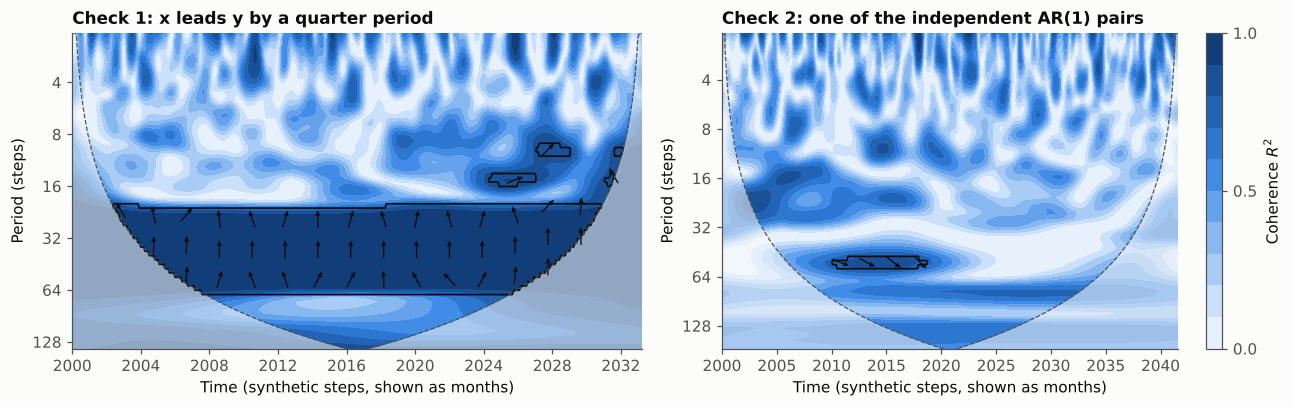

In [6]:
rng = np.random.default_rng(1)
t = np.arange(400)
x_lead = np.sin(2 * np.pi * t / 40) + 0.1 * rng.normal(size=400)
y_lag = np.sin(2 * np.pi * (t - 10) / 40) + 0.1 * rng.normal(size=400)
syn = wavelet_coherence(x_lead, y_lag, n_surrogates=200)
j40 = np.argmin(abs(syn["period"] - 40))
mean_phase = np.degrees(np.angle(np.mean(np.exp(1j * syn["phase"][j40, 100:300]))))
print(f"check 1: period {syn['period'][j40]:.1f}, mean coherence {syn['rsq'][j40, 100:300].mean():.3f}, "
      f"mean phase {mean_phase:+.1f} degrees (expected +90: x leads)")
assert 80 < mean_phase < 100

shares05, shares_fdr = [], []
for rep in range(20):
    a = ar1_surrogates(0.6, 500, 1, rng)[0].astype(float)
    b = ar1_surrogates(0.4, 500, 1, rng)[0].astype(float)
    null_check = wavelet_coherence(a, b, n_surrogates=200, seed=100 + rep)
    inside = null_check["inside"]
    shares05.append(np.mean(null_check["p"][inside] < 0.05))
    shares_fdr.append(np.mean(null_check["sig"][inside]))
print(f"check 2: 20 independent AR(1) pairs: on average {np.mean(shares05):.1%} of points with p < 0.05 "
      f"(expected about 5 %; range {min(shares05):.1%} to {max(shares05):.1%}), "
      f"{np.mean(shares_fdr):.2%} significant after FDR (largest {max(shares_fdr):.2%}; expected close to 0)")

times_syn = pd.date_range("2000-01-01", periods=400, freq="MS")
times_null = pd.date_range("2000-01-01", periods=500, freq="MS")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_coherence(axes[0], syn, times_syn, "Check 1: x leads y by a quarter period", "steps")
plot_coherence(axes[1], null_check, times_null, "Check 2: one of the independent AR(1) pairs", "steps",
               show_colorbar=True)
for ax in axes:
    ax.set_xlabel("Time (synthetic steps, shown as months)")
fig.tight_layout()
plt.show()

**What this tells us.** In the first check the arrows inside the black outline at period 40 point straight up, so
in every map below **up means the exogenous variable leads**. In the second check the colours show patches of high
coherence, because two smooth series always line up somewhere, but almost none of them survives the correction.
Those patches are what chance looks like.

## 5 · From maps to numbers

A map is rich but hard to compare across 18 pairs, so each map is summarised by bands of periods:

- **significant share:** the fraction of the band's area inside the COI that is significant after the FDR
  correction;
- **mean coherence** and **mean phase** inside the significant area, weighted by $R^2$. Phases are angles, so they
  are averaged as directions (a circular mean), $\bar\phi = \arg \sum R^2_n(s)\thinspace e^{i\phi_n(s)}$. The reading
  comes from the arrow table above, and the implied lead in months or days is $\bar\phi/(2\pi)$ times the typical
  period of the significant area (its $R^2$-weighted geometric mean period);
- **episodes:** the years with the largest significant share.

#### The verdict rule

Only bands that reach the forecast horizons count: bands whose longest period is at least the shortest horizon
(3 months for D4, 7 days for D2). The statistic is the largest significant share among those bands. A covariate is
labelled **keep** if the statistic is above the *keep threshold*, **weak** if it is above the *weak threshold*, and
**drop** otherwise. The thresholds are not guessed. The next cells measure how large the statistic gets for
*independent* series and set the thresholds from that, so we know how often the rule raises a false alarm.

In [7]:
def summarise_coherence(res, times, bands):
    """Turn one coherence map into numbers.

    bands: list of (label, low_period, high_period) in time units of the data.
    For each band: share of the COI area that is FDR-significant, mean
    coherence and circular-mean phase inside the significant area, and the
    implied lead of the exogenous variable (lead_fraction(phase) x the
    R^2-weighted geometric mean period of the significant points; positive =
    exogenous variable leads).
    """
    rows = []
    period, inside, sig = res["period"], res["inside"], res["sig"]
    for label, lo, hi in bands:
        rmask = (period >= lo) & (period < hi)
        area = inside[rmask].sum()
        s = sig[rmask] & inside[rmask]
        share = s.sum() / area if area else np.nan
        if s.any():
            ph = res["phase"][rmask][s]
            w = res["rsq"][rmask][s]
            mean_phase = np.angle(np.sum(w * np.exp(1j * ph)))
            per = np.broadcast_to(period[rmask][:, None], s.shape)[s]
            centre = np.exp(np.sum(w * np.log(per)) / np.sum(w))
            rows.append({"band": label, "sig_share": share,
                         "mean_coh_sig": float(w.mean()), "centre_period": float(centre),
                         "phase_deg": float(np.degrees(mean_phase)),
                         "lead_of_exog": float(lead_fraction(np.degrees(mean_phase)) * centre),
                         "reading": phase_reading(np.degrees(mean_phase))})
        else:
            rows.append({"band": label, "sig_share": share, "mean_coh_sig": np.nan,
                         "centre_period": np.nan, "phase_deg": np.nan, "lead_of_exog": np.nan,
                         "reading": "no significant area"})
    return rows


def lead_fraction(phase_deg):
    """Lead of the exogenous series in cycles, reading the phase as Aguiar-Conraria & Soares (2014).

    phi in (0, 90): in phase, exogenous leads;   phi in (-90, 0): in phase, target leads;
    phi in (90, 180): anti-phase, target leads;  phi in (-180, -90): anti-phase, exogenous leads.
    For anti-phase angles the lead is measured against the inverted series.
    """
    a = (phase_deg + 180) % 360 - 180
    return a / 360 if abs(a) <= 90 else (a - 180 * np.sign(a)) / 360


def phase_reading(phase_deg, tol=10):
    """Plain-language reading of a mean phase angle (exogenous series first)."""
    if phase_deg is None or np.isnan(phase_deg):
        return "no significant area"
    a = (phase_deg + 180) % 360 - 180
    if abs(a) <= tol:
        return "in phase, no clear lead"
    if abs(a) >= 180 - tol:
        return "anti-phase, no clear lead"
    relation = "in phase" if abs(a) < 90 else "anti-phase"
    leader = "exogenous leads" if lead_fraction(a) > 0 else "target leads"
    return f"{relation}, {leader}"


def episode_years(res, times, top=3):
    """Years with the largest share of significant area (inside the COI)."""
    import pandas as pd

    years = pd.DatetimeIndex(times).year
    s = (res["sig"] & res["inside"]).sum(axis=0)
    a = res["inside"].sum(axis=0)
    df = pd.DataFrame({"year": years, "sig": s, "area": a}).groupby("year").sum()
    df = df[df["area"] > 0]
    share = (df["sig"] / df["area"]).sort_values(ascending=False)
    return [int(y) for y in share.index[:top] if share[y] > 0]

In [8]:
def verdict(rows, shortest_horizon, keep, weak):
    eligible = [r for r in rows if r["hi"] >= shortest_horizon and not np.isnan(r["sig_share"])]
    best = max(eligible, key=lambda r: r["sig_share"])
    label = "keep" if best["sig_share"] >= keep else "weak" if best["sig_share"] >= weak else "drop"
    return label, best


def summarise_pair(res, times, bands, exog, target):
    rows = summarise_coherence(res, times, bands)
    for r, (_, lo, hi) in zip(rows, bands):
        r.update({"exogenous": exog, "target": target, "lo": lo, "hi": hi})
    inside = res["inside"]
    overall = float((res["sig"] & inside).sum() / inside.sum())
    return rows, overall, episode_years(res, times)

#### How often does chance pass the rule?

If 10 % of a band can be significant by chance, a fixed 10 % threshold would label many unrelated covariates
*keep*. Long periods are the risk. There the coherence is smoothed over years, so a single chance patch covers a
large share of a band that holds only a few cycles.

So we calibrate. For every pair of D4 and D2 (NAO and AO only: day length follows a fixed formula, so an AR(1) null
does not describe it), we simulate independent AR(1) pairs with the **same lag-1 coefficients and the same
length** as the real inputs, run exactly the same test and record the statistic: 210 null pairs for D4 and 40 for
D2. The 95th percentile of these values becomes the keep threshold and the 80th percentile the weak threshold
(never below 10 % and 5 %). An unrelated covariate is then labelled *keep* about 5 % of the time and *weak or
better* about 20 % of the time.

The simulation takes about 25 minutes on four cores, so its result is stored in
`results/tables/table_wca_null_calibration.csv` (made by `scripts/calibrate_wca_null.py`, which calls the
functions below). Set `RECALIBRATE = True` to recompute it here.

In [9]:
def band_share(res, lo, hi):
    """Share of the COI area with periods in [lo, hi) that is FDR-significant."""
    rmask = (res["period"] >= lo) & (res["period"] < hi)
    area = res["inside"][rmask].sum()
    return float((res["sig"][rmask] & res["inside"][rmask]).sum() / area) if area else np.nan


def null_best_shares(phi_x, phi_y, n, bands, shortest_horizon, n_pairs, n_surrogates=200, alpha=0.10, seed=0):
    """The verdict rule's statistic under independence.

    For n_pairs independent AR(1) pairs with coefficients (phi_x, phi_y) and
    length n, run the same coherence test and return, for each pair, the
    largest FDR-significant share among the bands that reach the horizons
    (upper period >= shortest_horizon). Its upper quantiles are the
    thresholds a real pair must beat.
    """
    rng = np.random.default_rng(seed)
    best = []
    for _ in range(n_pairs):
        a = ar1_surrogates(phi_x, n, 1, rng)[0].astype(float)
        b = ar1_surrogates(phi_y, n, 1, rng)[0].astype(float)
        res = wavelet_coherence(a, b, n_surrogates=n_surrogates, alpha=alpha, seed=int(rng.integers(2**31)))
        best.append(np.nanmax([band_share(res, lo, hi) for _, lo, hi in bands if hi >= shortest_horizon]))
    return np.array(best)


def calibrated_thresholds(null_best, keep_q=0.95, weak_q=0.80, keep_floor=0.10, weak_floor=0.05):
    """keep / weak thresholds: the null's 95th and 80th percentiles, never below 10 % and 5 %."""
    return {"keep": max(keep_floor, float(np.quantile(null_best, keep_q))),
            "weak": max(weak_floor, float(np.quantile(null_best, weak_q)))}

In [10]:
import subprocess

RECALIBRATE = False   # True: rerun the null simulation (about 25 min on 4 cores, longer on Colab's 2)
cal_path = RESULTS / "tables" / "table_wca_null_calibration.csv"
if RECALIBRATE or not cal_path.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "calibrate_wca_null.py")], check=True)
calibration = pd.read_csv(cal_path)
THRESHOLDS = {ds: calibrated_thresholds(g["best_share"]) for ds, g in calibration.groupby("dataset")}
summary_cal = calibration.groupby("dataset")["best_share"].agg(
    null_pairs="size", median="median", p80=lambda v: v.quantile(0.8), p95=lambda v: v.quantile(0.95),
    share_at_or_above_10pct=lambda v: (v >= 0.10).mean())
summary_cal["keep threshold"] = [THRESHOLDS[d]["keep"] for d in summary_cal.index]
summary_cal["weak threshold"] = [THRESHOLDS[d]["weak"] for d in summary_cal.index]
summary_cal.round(3)

,null_pairs,median,p80,p95,share_at_or_above_10pct,keep threshold,weak threshold
dataset,,,,,,,
D2,40,0.011,0.041,0.112,0.075,0.112,0.050
D4,210,0.006,0.057,0.216,0.133,0.216,0.057


## 6 · D4: metal prices and global drivers

#### Inputs

The AR(1) null describes stationary series, so each variable enters in the form closest to stationary: **log
changes** of the five metal prices and of the dollar index, **first differences** of the real rate, and the Kilian
index **as published** (it is already a deviation from trend). Coherence between changes describes how the
fluctuations move together, which is what a forecaster can use. Section 6c shows why levels would mislead.

#### What economics leads us to expect

These expectations are written down before the test, so that the test can confirm or reject them (Notebook 00
gives the economic reasoning):

- global activity coherent with metal prices at business-cycle periods (about 1.5 to 8 years), in phase or
  leading, and strongest for copper;
- the dollar in anti-phase (arrows pointing left): a stronger dollar goes with lower metal prices;
- the real rate in anti-phase, mainly at long periods;
- weaker, patchier coherence for nickel and lead, where supply shocks dominate.

In [11]:
d4 = SNAP["D4"].loc[:IN_END["D4"]]
D4_IN = pd.DataFrame({m: np.log(d4[m]).diff() for m in METALS})
D4_EX = pd.DataFrame({"global_activity": d4["global_activity"], "usd": np.log(d4["usd"]).diff(),
                      "real_rate_10y": d4["real_rate_10y"].diff()})
D4_IN, D4_EX = D4_IN.iloc[1:], D4_EX.iloc[1:]
BANDS_D4 = [("2-6 m", 2, 6), ("6-12 m", 6, 12), ("12-24 m", 12, 24), ("24-48 m", 24, 48), ("48-96 m", 48, 96)]

results_d4, rows_d4, t0 = {}, [], time.time()
for target in METALS:
    for exog in DRIVERS:
        res = wavelet_coherence(D4_EX[exog].to_numpy(), D4_IN[target].to_numpy(), n_surrogates=N_SURROGATES["D4"],
                                alpha=ALPHA, seed=2026)
        results_d4[(target, exog)] = res
        rows, overall, years = summarise_pair(res, D4_IN.index, BANDS_D4, exog, target)
        for r in rows:
            r.update({"overall_sig_share": overall, "top_years": ", ".join(map(str, years))})
        rows_d4 += rows
strength_d4 = pd.DataFrame(rows_d4)
print(f"15 maps with {N_SURROGATES['D4']} surrogates each in {time.time() - t0:.0f} s; "
      f"{len(D4_IN)} months ({D4_IN.index[0]:%b %Y} to {D4_IN.index[-1]:%b %Y})")

15 maps with 1000 surrogates each in 88 s; 498 months (Feb 1982 to Jul 2023)


### 6a · The 15 coherence maps

Rows are metals and columns are drivers. The colour shows the coherence $R^2$; black outlines mark areas that are
significant after the FDR correction at 10 %; faded areas lie outside the cone of influence. Inside the
significant areas the arrows read: right = in phase, left = anti-phase, **up = the driver leads**, down = the metal
leads.

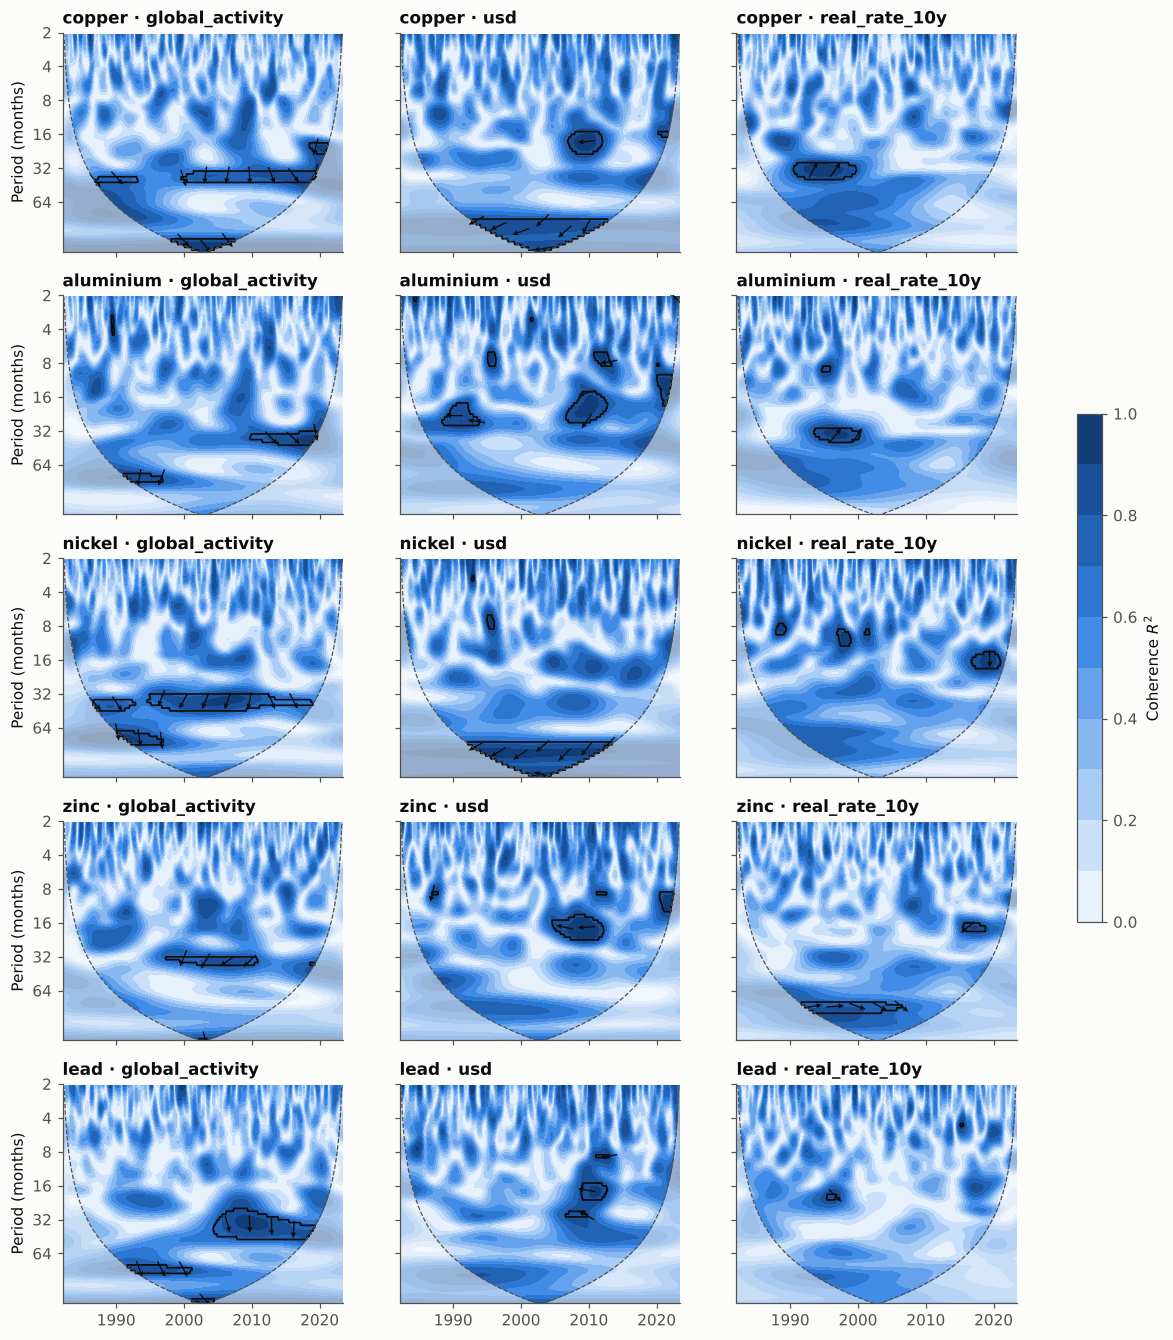

In [12]:
fig, axes = plt.subplots(5, 3, figsize=(14, 15), sharex=True, sharey=True)
for i, target in enumerate(METALS):
    for j, exog in enumerate(DRIVERS):
        mesh = plot_coherence(axes[i, j], results_d4[(target, exog)], D4_IN.index, f"{target} · {exog}", "months",
                       period_ticks=[2, 4, 8, 16, 32, 64])
        if j:
            axes[i, j].set_ylabel("")
axes[0, 0].xaxis.set_major_locator(mdates.YearLocator(10))       # shared x-axis: a tick every 10 years
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.colorbar(mesh, ax=axes, shrink=0.4, label="Coherence $R^2$")
fig.savefig(RESULTS / "figures" / "fig_ch03_02_wca_D4_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**What this tells us.** Significant coherence (the black outlines) is sparse, and most of it sits at periods of
two to four years, the business-cycle band. Global activity shows the longest patches, at 24 to 48 months: for
nickel from the early 1990s to the late 2010s, for lead from about 2005, and for copper in the 1980s and again
from the late 1990s. The dollar is significant mainly at 12 to 24 months around 2008 to 2012 (copper, zinc,
aluminium) and at about eight years along the bottom of the cone (copper, nickel). The real rate has a few
isolated islands. At periods of 2 to 12 months there is almost nothing beyond the scattered specks that chance
produces, which fits the fact that monthly changes in metal prices are close to unpredictable from one month to
the next.

A covariate can only help where it is coherent with the target, and only at periods that matter for the forecast
horizon. Here the coherent periods are mostly longer than the 3- to 12-month horizons, which already suggests that
the gains from these drivers will be modest.

### 6b · Strength summary and verdicts for D4

The heatmap gives the view at a glance: the share of each map's COI area that is significant. The table holds the
band-by-band numbers behind the verdicts.

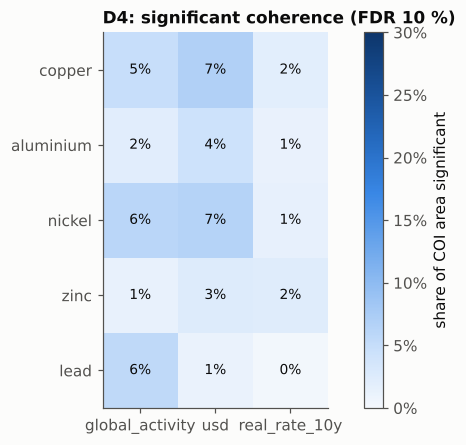

In [13]:
def heatmap(strength, targets, exogs, title, path):
    share = strength.groupby(["target", "exogenous"])["overall_sig_share"].first().unstack().loc[targets, exogs]
    fig, ax = plt.subplots(figsize=(1.6 * len(exogs) + 2, 0.55 * len(targets) + 1.4))
    im = ax.imshow(share, cmap=SEQUENTIAL, vmin=0, vmax=max(0.3, float(share.max().max())))
    ax.set_xticks(range(len(exogs)), exogs)
    ax.set_yticks(range(len(targets)), targets)
    for i in range(len(targets)):
        for j in range(len(exogs)):
            v = share.iat[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.18 else INK)
    ax.set_title(title, loc="left")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="share of COI area significant", format=PercentFormatter(1.0, decimals=0))
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    return share


share_d4 = heatmap(strength_d4, list(METALS), list(DRIVERS), "D4: significant coherence (FDR 10 %)",
                   RESULTS / "figures" / "fig_ch03_02_wca_D4_heatmap.png")

In [14]:
def verdict_table(strength, shortest_horizon, unit, thresholds):
    out = []
    for (target, exog), g in strength.groupby(["target", "exogenous"], sort=False):
        label, best = verdict(g.to_dict("records"), shortest_horizon, thresholds["keep"], thresholds["weak"])
        sig_bands = g.loc[(g["sig_share"] >= thresholds["keep"]) & (g["hi"] >= shortest_horizon), "band"].tolist()
        out.append({"target": target, "exogenous": exog, "verdict": label,
                    "best band": best["band"], "best band share": round(best["sig_share"], 3),
                    "bands above keep threshold": ", ".join(sig_bands) or "none",
                    "phase in best band": best["reading"],
                    f"typical period ({unit})": None if np.isnan(best["centre_period"]) else round(best["centre_period"], 1),
                    f"lead of exogenous ({unit})": None if np.isnan(best["lead_of_exog"]) else round(best["lead_of_exog"], 1),
                    "overall share": round(g["overall_sig_share"].iloc[0], 3),
                    "years with most significant area": g["top_years"].iloc[0]})
    return pd.DataFrame(out)


(RESULTS / "tables").mkdir(parents=True, exist_ok=True)
strength_d4.to_csv(RESULTS / "tables" / "table_wca_strength_D4.csv", index=False)
print(f"D4 thresholds: keep >= {THRESHOLDS['D4']['keep']:.1%}, weak >= {THRESHOLDS['D4']['weak']:.1%}")
verdicts_d4 = verdict_table(strength_d4, min(HORIZONS["monthly"]), "months", THRESHOLDS["D4"])
verdicts_d4

D4 thresholds: keep >= 21.6%, weak >= 5.7%


,target,exogenous,verdict,best band,best band share,bands above keep threshold,phase in best band,typical period (months),lead of exogenous (months),overall share,years with most significant area
0,copper,global_activity,weak,24-48 m,0.216,none,"in phase, target leads",38.5,-8.4,0.049,"2002, 2003, 2004"
1,copper,usd,weak,12-24 m,0.081,none,"anti-phase, no clear lead",18.7,0.4,0.069,"2008, 2009, 2010"
2,copper,real_rate_10y,weak,24-48 m,0.122,none,"in phase, exogenous leads",33.8,5.5,0.019,"1993, 1992, 1994"
3,aluminium,global_activity,weak,24-48 m,0.085,none,"in phase, target leads",37.3,-5.5,0.020,"2018, 2017, 2016"
4,aluminium,usd,weak,12-24 m,0.137,none,"anti-phase, exogenous leads",18.8,1.1,0.043,"2021, 2011, 2009"
5,aluminium,real_rate_10y,weak,24-48 m,0.069,none,"in phase, exogenous leads",34.7,4.8,0.012,"1995, 1996, 1997"
6,nickel,global_activity,keep,24-48 m,0.326,24-48 m,"anti-phase, exogenous leads",38.1,8.7,0.061,"1991, 1995, 1992"
7,nickel,usd,weak,48-96 m,0.135,none,"anti-phase, exogenous leads",90.9,9.6,0.065,"2002, 2003, 2001"
8,nickel,real_rate_10y,drop,12-24 m,0.046,none,"anti-phase, exogenous leads",16.3,3.9,0.014,"2019, 2020, 2018"
9,zinc,global_activity,weak,24-48 m,0.085,none,"anti-phase, exogenous leads",34.8,5.0,0.014,"2002, 2003, 2009"


In [15]:
for exog in DRIVERS:
    v = verdicts_d4[verdicts_d4["exogenous"] == exog]
    counts = v["verdict"].value_counts().reindex(["keep", "weak", "drop"]).fillna(0).astype(int)
    phases = v.loc[v["verdict"] != "drop", "phase in best band"].value_counts()
    print(f"{exog}: keep for {counts['keep']} metals, weak for {counts['weak']}, drop for {counts['drop']}; "
          f"phase where related: {', '.join(f'{k} ({n})' for k, n in phases.items()) or 'n/a'}")

global_activity: keep for 2 metals, weak for 3, drop for 0; phase where related: in phase, target leads (3), anti-phase, exogenous leads (2)
usd: keep for 0 metals, weak for 4, drop for 1; phase where related: anti-phase, no clear lead (2), anti-phase, exogenous leads (2)
real_rate_10y: keep for 0 metals, weak for 3, drop for 2; phase where related: in phase, exogenous leads (2), in phase, target leads (1)


**What this tells us.** With the calibrated thresholds (keep at 21.6 %, weak at 5.7 %), global activity is the
only driver kept, for nickel (32.6 % of the 24 to 48 month band) and lead (28.1 %). Copper's 21.6 % misses the line
by 0.03 percentage points, so in practice it is a tie. Resampling the 210 null pairs puts the 95th percentile
anywhere between about 13 % and 26 %, so treat copper as a borderline case. The dollar and the real rate are
*weak* for most metals, and are dropped for lead (and for nickel with the real rate).

Read the phases with one fact in mind. The metals enter as monthly changes, but global activity enters as a level
(it is already a deviation from trend). A change runs a quarter of a cycle (90°) ahead of its own level, so an
angle near −90° means that the metal price *level* moves together with global activity. All five metals sit
between −53° and −129° in the 24 to 48 month band. The labels switch between *in phase, target leads* (copper,
aluminium, lead) and *anti-phase, exogenous leads* (nickel, zinc) only because the angle falls on either side of
−90°. Corrected for the quarter cycle, price levels and global activity move within about four months of each
other: the demand-driven co-movement that economists expect.

At 12 to 24 months the dollar is in anti-phase with copper, aluminium, zinc and lead (within about 20° of opposite
phase, with no clear lead): a stronger dollar goes with lower dollar prices of metals, the familiar inverse
relation. Nickel's link to the dollar shows only at about eight years. The real rate is in phase with copper and
aluminium at about three years (+50° to +59°). That is the opposite sign to the carrying-cost argument (higher real
rates make holding stocks dearer and push prices down), so it more likely reflects real rates and metal prices
both rising in economic expansions.

Compared with the expectations written down before the test: the dollar's anti-phase is confirmed; global
activity is coherent at business-cycle periods as expected, but it is strongest for nickel and lead, not copper;
and the real rate is in phase, not in anti-phase. Two of the four expectations failed, which is exactly why we
test them rather than assume them.

On coherence, then, global activity is the driver most likely to help, and the dollar and the real rate are
unlikely to add much. All three still go into the forecasting experiments (see the note in Section 11). Because
global activity moves with metal prices rather than clearly ahead of them, a model that receives only its past
values should gain little.

### 6c · Why changes and not levels

Here is the same pair, copper and global activity, with copper in **log levels**. Two trending or slowly wandering
series share power at long periods, so the map lights up there even when their year-to-year fluctuations are
unrelated, and an AR(1) null with $\phi$ close to 1 describes a trending price poorly. This is the wavelet version
of the spurious-regression problem: regress one random walk on another and you will often find a "significant"
relation that is not there.

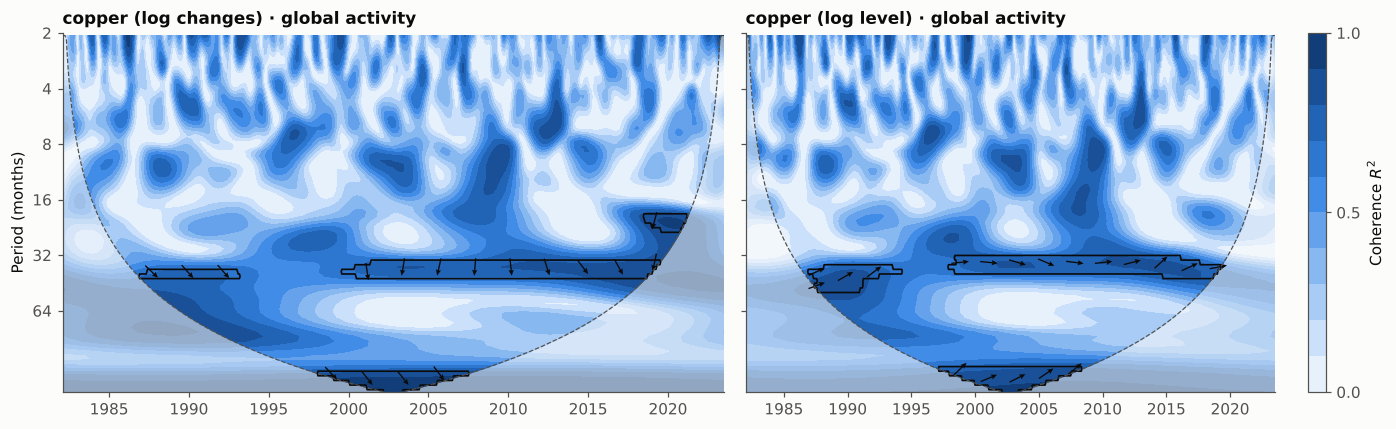

AR(1) coefficient of log copper: 0.996; significant share, levels: 5.9% vs changes: 4.9%


In [16]:
lev = wavelet_coherence(d4["global_activity"].to_numpy(), np.log(d4["copper"]).to_numpy(),
                        n_surrogates=N_SURROGATES["D4"], alpha=ALPHA, seed=2026)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_coherence(axes[0], results_d4[("copper", "global_activity")], D4_IN.index,
               "copper (log changes) · global activity", "months", period_ticks=[2, 4, 8, 16, 32, 64])
plot_coherence(axes[1], lev, d4.index, "copper (log level) · global activity", "months",
               period_ticks=[2, 4, 8, 16, 32, 64], show_colorbar=True)
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()
print(f"AR(1) coefficient of log copper: {lev['phi_y']:.3f}; significant share, levels: "
      f"{(lev['sig'] & lev['inside']).sum() / lev['inside'].sum():.1%} vs changes: "
      f"{share_d4.loc['copper', 'global_activity']:.1%}")

## 7 · D2: temperature and its drivers

#### Inputs

Daily temperature (stationary around its annual cycle, as Notebook 01 found) against the NAO index, the AO index
and day length, all as published. Day length stands in for the Fourier terms: both carry the same annual cycle,
so one test covers both. The wavelet bands are not tested. They are built from the temperature itself, so they
are coherent with it by construction; their value is measured directly, as the gain in forecast accuracy, in the
forecasting notebooks.

#### What we expect

- NAO coherent with temperature mainly in winter, at periods of days to weeks, and in phase, because a positive
  NAO brings mild westerly air.
- AO much like NAO. The two indices describe overlapping pressure patterns, so the notebook checks whether their
  maps coincide here, and Section 9 measures how much of their information about temperature is shared.
- Day length coherent at the annual period, with temperature lagging by about a month.

In [17]:
d2 = SNAP["D2"].loc[:IN_END["D2"]]
BANDS_D2 = [("2-8 d", 2, 8), ("8-32 d", 8, 32), ("32-128 d", 32, 128), ("128-512 d", 128, 512), (">512 d", 512, 1e9)]
results_d2, rows_d2, t0 = {}, [], time.time()
for exog in ["nao", "ao", "daylength_h"]:
    res = wavelet_coherence(d2[exog].to_numpy(), d2["temp"].to_numpy(), n_surrogates=N_SURROGATES["D2"],
                            alpha=ALPHA, seed=2026)
    results_d2[exog] = res
    rows, overall, years = summarise_pair(res, d2.index, BANDS_D2, exog, "temp")
    for r in rows:
        r.update({"overall_sig_share": overall, "top_years": ", ".join(map(str, years))})
    rows_d2 += rows
    print(f"temp · {exog}: {time.time() - t0:.0f} s")
strength_d2 = pd.DataFrame(rows_d2)

temp · nao: 30 s


temp · ao: 61 s


temp · daylength_h: 92 s


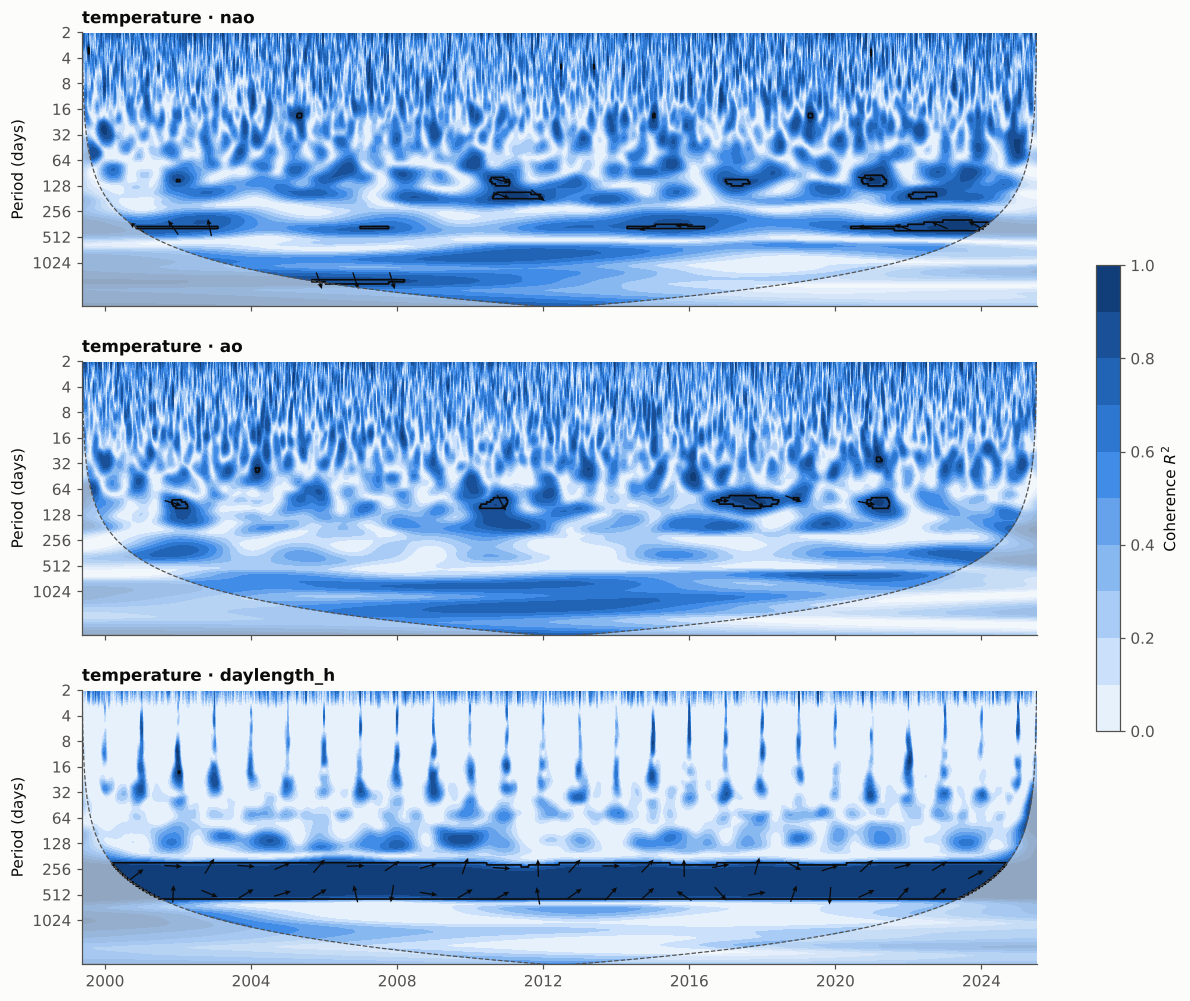

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, exog in zip(axes, ["nao", "ao", "daylength_h"]):
    mesh = plot_coherence(ax, results_d2[exog], d2.index, f"temperature · {exog}", "days",
                   period_ticks=[2, 4, 8, 16, 32, 64, 128, 256, 512, 1024], arrow_every=365)
fig.colorbar(mesh, ax=axes, shrink=0.5, label="Coherence $R^2$")
fig.savefig(RESULTS / "figures" / "fig_ch03_02_wca_D2.png", dpi=150, bbox_inches="tight")
plt.show()

**What this tells us.** Day length dominates. A solid band of coherence close to 1 at the annual period runs
through the whole sample, with arrows pointing right and slightly up: in phase, with temperature following day
length by about a month (mean phase +33°, a lag of 30 days). This is the seasonal lag of a climate whose land and
sea store a lot of heat. NAO and AO show only small, scattered islands, mostly at periods of 64 to 512 days.

The winter coupling we expected at periods of days to weeks does not appear as significant area. A likely reason
is that coherence at a given period needs the relation to hold for several cycles. An effect that switches on each
winter and off each summer is diluted, and the false discovery rate correction over 10,000 days then removes the
small islands that remain. A winter-only analysis could still find it; this screen does not.

The annual cycle is the main structure in daily temperature, and it is known in advance (day length and the
Fourier terms). A model that receives those inputs, or that learns the cycle from a long context, has the main
source of skill covered.

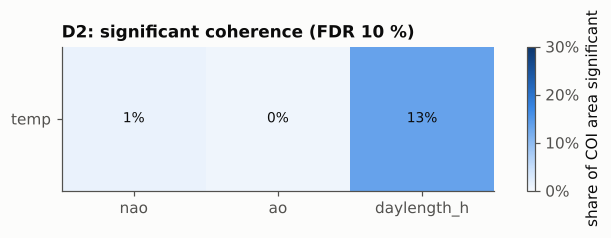

D2 thresholds: keep >= 11.2%, weak >= 5.0%


,target,exogenous,verdict,best band,best band share,bands above keep threshold,phase in best band,typical period (days),lead of exogenous (days),overall share,years with most significant area
0,temp,nao,drop,128-512 d,0.038,none,"anti-phase, target leads",312.8,-21.9,0.011,"2022, 2023, 2021"
1,temp,ao,drop,32-128 d,0.023,none,"in phase, target leads",90.9,-7.1,0.005,"2017, 2021, 2010"
2,temp,daylength_h,keep,128-512 d,0.604,128-512 d,"in phase, exogenous leads",336.1,30.5,0.134,"2022, 2002, 2001"


In [19]:
share_d2 = heatmap(strength_d2, ["temp"], ["nao", "ao", "daylength_h"], "D2: significant coherence (FDR 10 %)",
                   RESULTS / "figures" / "fig_ch03_02_wca_D2_heatmap.png")
strength_d2.to_csv(RESULTS / "tables" / "table_wca_strength_D2.csv", index=False)
print(f"D2 thresholds: keep >= {THRESHOLDS['D2']['keep']:.1%}, weak >= {THRESHOLDS['D2']['weak']:.1%}")
verdicts_d2 = verdict_table(strength_d2, min(HORIZONS["daily"]), "days", THRESHOLDS["D2"])
verdicts_d2

#### Do NAO and AO light up the same areas?

If their maps coincide, giving a model both adds a redundant input. The overlap of the two significant areas $A$
and $B$ is measured by the Jaccard index,

$$J = \frac{|A \cap B|}{|A \cup B|},$$

which is 1 for identical areas and 0 for areas that do not overlap at all. Section 9 asks the sharper question of
how much of their information about tomorrow's temperature is shared.

In [20]:
a_sig = results_d2["nao"]["sig"] & results_d2["nao"]["inside"]
b_sig = results_d2["ao"]["sig"] & results_d2["ao"]["inside"]
jaccard = (a_sig & b_sig).sum() / max((a_sig | b_sig).sum(), 1)
print(f"NAO vs AO maps: Jaccard overlap of the significant areas {jaccard:.2f} -> "
      f"{'the maps largely coincide' if jaccard >= 0.5 else 'the significant areas are mostly different'}")

NAO vs AO maps: Jaccard overlap of the significant areas 0.02 -> the significant areas are mostly different


**What this tells us.** Day length is kept: 60.4 % of its best band is significant, far above the calibrated keep
line of 11.2 %. NAO (3.8 %) and AO (2.3 %) fall below the weak line of 5 %. Their significant areas barely overlap
(Jaccard index 0.02), so on coherence alone they would look like distinct inputs; Section 9 shows that their
information about tomorrow's temperature is in fact mostly shared. The phase readings for NAO and AO come from
tiny areas and should not be read as physics.

On coherence alone, then, the climate indices would be rated unlikely to help. Sections 8 to 10 test them again
with predictive tools, which can detect a modest, steady day-to-day influence that never forms large patches of
high coherence.

## 8 · Granger causality: linear, non-linear and by time scale

Coherence says that two series move together at some periods. It does not say whether the past of the covariate
helps to predict the target, and that is what a forecaster needs. Granger causality asks exactly this: $x$
*Granger-causes* $y$ if the past of $x$ improves the forecast of $y$ beyond what the past of $y$ already gives. The
word "causality" is a little misleading, because the test measures predictive help, not a physical or economic
mechanism. We use three versions that look for three kinds of help.

#### Linear Granger test

Fit a two-variable vector autoregression (VAR) with lag order $p$. The equation for the target is

$$y_t = c + \sum_{i=1}^{p} a_i\thinspace y_{t-i} + \sum_{i=1}^{p} b_i\thinspace x_{t-i} + \varepsilon_t, \qquad H_0: b_1 = \dots = b_p = 0. \tag{G1}$$

If none of the $b_i$ matters, the past of $x$ adds nothing. The lag $p$ is chosen by the Akaike criterion of the
target's own autoregression (up to 12 months for D4 and 21 days for D2), so the choice never looks at $x$. In the
simulation of Section 8a, choosing $p$ from the full VAR let the data pick lags where $x$ happened to fit, and the
test then rejected about 7 % of unrelated pairs instead of 5 %. The test statistic is a Wald statistic,

$$F = \frac{1}{p}\thinspace \hat b^\top \big(R\thinspace \hat V R^\top\big)^{-1} \hat b,$$

compared with an $F(p,\thinspace n - 2p - 1)$ distribution. Here $\hat b$ is the vector of the estimated $b_i$, the matrix
$R$ picks them out of the full coefficient vector, and $\hat V$ is the HC3 covariance matrix, which stays valid when
the size of the errors changes over time. Metal prices have calm and turbulent periods, so this matters.

#### Non-linear Granger test (Diks–Panchenko)

The linear test cannot see help that comes through a curve, for instance when large moves of $x$ in either
direction matter. The non-linear test first removes all linear dynamics, by working on the residuals of the VAR,
and then checks whether $Z = y_t$ is independent of $X = x_{t-1}$ once $Y = y_{t-1}$ is known. If it is, the joint
density factorises as $f_{X,Y,Z}\thinspace f_Y = f_{X,Y}\thinspace f_{Y,Z}$, so the statistic measures the average departure from
that equality. With $W_i = (X_i, Y_i, Z_i)$,

$$T_n(\varepsilon) = \frac{1}{n} \sum_{i=1}^{n} \Big[ \hat f_{X,Y,Z}(W_i)\thinspace \hat f_Y(Y_i) - \hat f_{X,Y}(X_i, Y_i)\thinspace \hat f_{Y,Z}(Y_i, Z_i) \Big], \tag{G2}$$

$$\hat f_V(V_i) = \frac{(2\varepsilon)^{-d_V}}{n - 1} \sum_{j \ne i} \mathrm I\big(\lVert V_i - V_j \rVert_\infty \le \varepsilon\big).$$

Here $\mathrm I(\cdot)$ is 1 when the condition inside holds and 0 otherwise. Each density estimate $\hat f_V$ counts
the neighbours of observation $i$ inside a box of half-width $\varepsilon$
in the $d_V$ dimensions of the variables $V$ involved. The residuals are scaled to unit variance, and
$\varepsilon = 8\thinspace n^{-2/7}$, the bandwidth the test's authors recommend (1.33 for the 533 months of D4, 0.58 for
the 9,550 days of D2). Then $\sqrt{n}\thinspace T_n / S_n$ is approximately standard normal, where $S_n^2$ is nine times
the long-run variance of the per-observation terms (Bartlett weights over $\lfloor n^{1/4} \rfloor$ lags); large
values reject. The original test scales the sum by $(n-1)/(n(n-2))$ instead of $1/n$, which makes no difference at
these sample sizes.

#### Granger causality by time scale

Both series are split into the causal Haar wavelet bands of Notebook 01, equation (W2), with periods of 2 to 8, 8
to 32 and 32 to 128 steps. Equation (G1) is then estimated band by band. For example: does the 8-to-32-month part
of global activity help predict the 8-to-32-month part of copper? Two cautions apply.

1. The bands must be **causal**, built from past values only. A two-sided filter would put future values of $x$
   into its "past" band values and create causality out of nothing.
2. Filtered series are smooth, so the model needs many lags and the $F$ distribution no longer holds; in practice
   filtering can change the conclusions of Granger tests for this reason (see References).

The p-value therefore comes from **surrogates**: $x$ is replaced by a phase-randomised copy,

$$\tilde x_t = \bar x + \frac{1}{n} \sum_{k} \lvert \hat X_k \rvert\thinspace e^{\thinspace i (2 \pi k t / n + \theta_k)}, \qquad \theta_k \sim U(0, 2\pi), \quad \theta_{-k} = -\theta_k, \tag{G3}$$

where $\hat X_k$ is the discrete Fourier transform of $x$. Each frequency keeps its strength but gets a random
phase (the condition $\theta_{-k} = -\theta_k$ keeps the copy real). The copy therefore has the same power spectrum,
and so the same autocorrelation, as $x$, but no link with $y$. Repeating the whole band test $B$ times on such
copies gives the p-value

$$p = \frac{1 + \lvert\lbrace\tilde F \ge F\rbrace\rvert}{1 + B},$$

where the bars count the copies whose statistic $\tilde F$ is at least the observed $F$.

Read the bands as a description of where the predictive help sits, not as separate causal channels.

#### Multiple testing

Each column of results (linear, non-linear and each band) is one family of tests and gets the Benjamini–Hochberg
correction at 10 %, as the coherence maps do. The tables report the adjusted p-values, called q-values.

#### Inputs

D4 uses the same inputs as Section 6. All are stationary: the augmented Dickey–Fuller test rejects a unit root for
each driver input at 5 %, and the metal inputs are log changes. For D2 the target is the **temperature anomaly**:
the temperature minus its annual cycle, fitted with the $K = 2$ Fourier terms on the in-sample period. Day length
is not tested. It is a fixed function of the calendar, so it can be forecast perfectly from the date alone, and
asking whether its past improves the forecast means nothing beyond the annual cycle that has already been removed.

In [21]:
import numpy as np
from scipy import stats
from statsmodels.regression.linear_model import OLS


def lag_matrix(v, p):
    """Columns v[t-1], ..., v[t-p] for t = p, ..., n - 1."""
    v = np.asarray(v, float)
    return np.column_stack([v[p - k: len(v) - k] for k in range(1, p + 1)])


def select_lag(y, max_lag):
    """Lag order p of the target's own autoregression, by AIC on a common sample.

    The choice looks only at y, never at x: choosing p from a model that already
    contains x lets the data pick lags where x happens to fit, and the test then
    rejects too often (about 7 % instead of 5 % in simulations).
    """
    y = np.asarray(y, float)
    target = y[max_lag:]
    best, best_aic = 1, np.inf
    for p in range(1, max_lag + 1):
        design = np.column_stack([np.ones(len(target)), lag_matrix(y, max_lag)[:, :p]])
        rss = np.sum((target - design @ np.linalg.lstsq(design, target, rcond=None)[0]) ** 2)
        aic = len(target) * np.log(rss / len(target)) + 2 * (p + 1)
        if aic < best_aic:
            best, best_aic = p, aic
    return best


def granger_linear(y, x, max_lag, lag=None):
    """Does the past of x improve a linear forecast of y beyond the past of y?

    Model y_t = c + sum_i a_i y_{t-i} + sum_i b_i x_{t-i} + e_t, H0: b_1 = ... = b_p = 0,
    Wald F test with heteroskedasticity-robust (HC3) covariance; p from the AIC of
    y's own autoregression. Also returns the residuals of both VAR equations, the
    input of the non-linear test.
    """
    y, x = np.asarray(y, float), np.asarray(x, float)
    p = lag or select_lag(y, max_lag)
    design = np.column_stack([np.ones(len(y) - p), lag_matrix(y, p), lag_matrix(x, p)])
    fit_y = OLS(y[p:], design).fit(cov_type="HC3")
    restriction = np.zeros((p, design.shape[1]))
    restriction[:, 1 + p:] = np.eye(p)
    wald = fit_y.wald_test(restriction, use_f=True, scalar=True)
    fit_x = OLS(x[p:], design).fit()
    return {"lag": p, "F": float(wald.statistic), "p_value": float(wald.pvalue),
            "resid_y": fit_y.resid, "resid_x": fit_x.resid}


def _standardise(v):
    v = np.asarray(v, float)
    return (v - v.mean()) / v.std(ddof=1)


def diks_panchenko(x, y, eps=None, chunk=1500):
    """Diks & Panchenko (2006) test of H0: x does not Granger-cause y (lx = ly = 1).

    With X = x_{t-1}, Y = y_{t-1}, Z = y_t and local densities estimated by counting
    neighbours within eps (sup norm) on standardised data,
        T_n = mean_i [ f_XYZ(i) f_Y(i) - f_XY(i) f_YZ(i) ],
    which is zero under H0. sqrt(n) T_n / S_n is asymptotically N(0, 1); S_n^2 is 9 times
    the long-run variance of the U-statistic projection, with Bartlett weights and
    floor(n^(1/4)) lags. One-sided: large values reject.
    """
    x, y = _standardise(x), _standardise(y)
    X, Y, Z = x[:-1], y[:-1], y[1:]
    n = len(Z)
    eps = 8.0 * n ** (-2 / 7) if eps is None else eps

    def blocks():
        for start in range(0, n, chunk):
            rows = slice(start, min(start + chunk, n))
            ax = np.abs(X[rows, None] - X[None, :]) <= eps
            ay = np.abs(Y[rows, None] - Y[None, :]) <= eps
            az = np.abs(Z[rows, None] - Z[None, :]) <= eps
            ay[np.arange(ay.shape[0]), np.arange(rows.start, rows.stop)] = False   # j != i
            axy, ayz = ax & ay, ay & az
            yield rows, ay, axy, ayz, axy & az

    counts = {k: np.zeros(n) for k in ("y", "xy", "yz", "xyz")}
    for rows, ay, axy, ayz, axyz in blocks():
        for k, a in zip(("y", "xy", "yz", "xyz"), (ay, axy, ayz, axyz)):
            counts[k][rows] = a.sum(axis=1)
    cy, cxy, cyz, cxyz = (counts[k] for k in ("y", "xy", "yz", "xyz"))
    cross = np.zeros(n)
    for rows, ay, axy, ayz, axyz in blocks():
        cross[rows] = ay @ cxyz + axyz @ cy - ayz @ cxy - axy @ cyz
    scale = 2.0 / (2 * eps) ** 4 / (6.0 * (n - 1) ** 2)
    h = scale * (cxyz * cy - cxy * cyz + cross)
    t_n = h.mean()
    hc = h - t_n
    k_max = int(np.floor(n ** 0.25))
    weights = np.concatenate([[1.0], 2.0 * (1.0 - np.arange(1, k_max) / k_max)])
    autocov = np.array([np.dot(hc[k:], hc[:n - k]) / (n - k) for k in range(k_max)])
    variance = 9.0 * np.dot(weights, autocov)
    t_stat = t_n * np.sqrt(n) / np.sqrt(variance)
    return {"eps": eps, "T": t_n, "t_stat": float(t_stat), "p_value": float(stats.norm.sf(t_stat))}

In [22]:
from ch03_dataprep.features import causal_haar_modwt


def phase_randomise(v, rng):
    """Surrogate with the same mean and power spectrum as v and random Fourier phases."""
    v = np.asarray(v, float)
    spec = np.fft.rfft(v - v.mean())
    phases = rng.uniform(0, 2 * np.pi, len(spec))
    phases[0] = 0.0
    if len(v) % 2 == 0:
        phases[-1] = 0.0
    return np.fft.irfft(np.abs(spec) * np.exp(1j * phases), n=len(v)) + v.mean()


def scale_bands(v, unit):
    """Causal Haar MODWT bands W1+W2, W3+W4, W5+W6 (periods 2-8, 8-32, 32-128 steps)."""
    c = causal_haar_modwt(np.asarray(v, float), levels=6)
    return {f"2-8 {unit}": c["W1"] + c["W2"], f"8-32 {unit}": c["W3"] + c["W4"],
            f"32-128 {unit}": c["W5"] + c["W6"]}


def _f_stat(y, own, other, p):
    """Classical Granger F statistic, given the restricted design `own`."""
    full = np.column_stack([own, lag_matrix(other, p)])
    target = y[p:]
    rss_r = np.sum((target - own @ np.linalg.lstsq(own, target, rcond=None)[0]) ** 2)
    rss_u = np.sum((target - full @ np.linalg.lstsq(full, target, rcond=None)[0]) ** 2)
    dof = len(target) - full.shape[1]
    return ((rss_r - rss_u) / p) / (rss_u / dof)


def wavelet_granger(y, x, unit, max_lag, n_surrogates=199, seed=0):
    """Granger F test band by band, with a phase-randomised surrogate p-value per band."""
    burn = 2 ** 6 - 1                                  # first 63 values depend on the start
    yb = {k: v[burn:] for k, v in scale_bands(y, unit).items()}
    xb = {k: v[burn:] for k, v in scale_bands(x, unit).items()}
    rng = np.random.default_rng(seed)
    setup = {}
    for band in yb:
        p = select_lag(yb[band], max_lag)
        own = np.column_stack([np.ones(len(yb[band]) - p), lag_matrix(yb[band], p)])
        setup[band] = (p, own, _f_stat(yb[band], own, xb[band], p))
    null = {band: [] for band in yb}
    for _ in range(n_surrogates):
        sb = scale_bands(phase_randomise(x, rng), unit)
        for band, (p, own, _) in setup.items():
            null[band].append(_f_stat(yb[band], own, sb[band][burn:], p))
    out = []
    for band, (p, own, f_obs) in setup.items():
        exceed = int(np.sum(np.asarray(null[band]) >= f_obs))
        out.append({"band": band, "lag": p, "F": f_obs, "null_F_95": float(np.quantile(null[band], 0.95)),
                    "p_value": (1 + exceed) / (1 + n_surrogates)})
    return out

In [23]:
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller

N_SURR_GC = {"D4": 999, "D2": 199}   # phase-randomised surrogates per band test
MAX_LAG = {"D4": 12, "D2": 21}       # longest VAR lag searched by AIC: one year, three weeks


def add_q(table):
    # Benjamini-Hochberg q-values, one family per p-value column
    for col in [c for c in table.columns if c.endswith(" p")]:
        table[col[:-2] + " q"] = multipletests(table[col].to_numpy(), method="fdr_bh")[1]
    return table


print("ADF p-values of the D4 driver inputs: "
      + ", ".join(f"{c} {adfuller(D4_EX[c], autolag='AIC')[1]:.3f}" for c in DRIVERS))
fourier_cols = [c for c in d2.columns if c.startswith("fourier_")]
design = np.column_stack([np.ones(len(d2)), d2[fourier_cols]])
anomaly = d2["temp"] - design @ np.linalg.lstsq(design, d2["temp"].to_numpy(), rcond=None)[0]
print(f"D2 temperature anomaly: sd {anomaly.std():.2f} C against {d2['temp'].std():.2f} C for the temperature "
      f"({len(fourier_cols)} Fourier terms removed)")

ADF p-values of the D4 driver inputs: global_activity 0.011, usd 0.000, real_rate_10y 0.000
D2 temperature anomaly: sd 2.62 C against 5.16 C for the temperature (4 Fourier terms removed)


### 8a · Checks on simulated data

Before the real data, each test runs on simulated pairs where the right answer is known: unrelated pairs (a test
at the 5 % level should reject about 5 % of them), a linear link, a link through $x^2$ that has no linear
correlation, and a link that works only through the 24-month average of $x$.

In [24]:
def ar1(n, phi, rng):
    e, v = rng.standard_normal(n + 200), np.zeros(n + 200)
    for t in range(1, n + 200):
        v[t] = phi * v[t - 1] + e[t]
    return v[200:]


rng, n, t0 = np.random.default_rng(7), 500, time.time()
lin_null, lin_alt, dp_null, dp_alt, lin_sq = [], [], [], [], []
for r in range(200):
    x = ar1(n, 0.5, rng)
    lin_null.append(granger_linear(ar1(n, 0.5, rng), x, 6)["p_value"])
    y, e = np.zeros(n), rng.standard_normal(n)
    for t in range(1, n):
        y[t] = 0.5 * y[t - 1] + 0.2 * x[t - 1] + e[t]          # x enters linearly
    lin_alt.append(granger_linear(y, x, 6)["p_value"])
for r in range(100):
    x = ar1(n, 0.3, rng)
    y, z, h = np.zeros(n), rng.standard_normal(n), np.ones(n)
    for t in range(1, n):                                      # unrelated, with volatility clustering
        h[t] = 0.3 + 0.5 * h[t - 1] * z[t - 1] ** 2
        y[t] = 0.3 * y[t - 1] + np.sqrt(h[t]) * z[t]
    g = granger_linear(y, x, 6)
    dp_null.append(diks_panchenko(g["resid_x"], g["resid_y"])["p_value"])
    y, e = np.zeros(n), rng.standard_normal(n)
    for t in range(1, n):                                      # x enters through x squared
        y[t] = 0.3 * y[t - 1] + 0.5 * (x[t - 1] ** 2 - 1 / (1 - 0.3 ** 2)) + e[t]
    g = granger_linear(y, x, 6)
    lin_sq.append(g["p_value"])
    dp_alt.append(diks_panchenko(g["resid_x"], g["resid_y"])["p_value"])
wav_null = np.array([[b["p_value"] for b in wavelet_granger(ar1(534, 0.3, rng), ar1(534, 0.9, rng), "m", 12, 99, seed=r)]
                     for r in range(40)])
x = ar1(560, 0.3, rng)
slow = pd.Series(x).rolling(24).mean().shift(1)              # y follows the average of x over the past 24 months
y = (1.5 * slow + ar1(560, 0.3, rng)).to_numpy()
ok = slow.notna().to_numpy()
wav_alt = wavelet_granger(y[ok], x[ok], "m", 12, 199, seed=1)

rate = lambda p: float(np.mean(np.asarray(p) < 0.05))
checks = pd.DataFrame(
    [("linear", "unrelated pair", rate(lin_null), "about 5 %"),
     ("linear", "x enters y linearly", rate(lin_alt), "close to 100 %"),
     ("non-linear", "unrelated, y with volatility clustering", rate(dp_null), "5 % or less"),
     ("non-linear", "y responds to x squared", rate(dp_alt), "high"),
     ("linear", "y responds to x squared", rate(lin_sq), "low: the linear test is nearly blind to it")]
    + [(f"by scale, {b['band']}", "unrelated pair (40 runs)", float(v), "about 5 %")
       for b, v in zip(wav_alt, (wav_null < 0.05).mean(axis=0))]
    + [(f"by scale, {b['band']}", "y follows the 24-month average of x", b["p_value"], "small only for 32-128 m (p-value)")
       for b in wav_alt],
    columns=["test", "simulated case", "share rejected at 5 % (or p-value)", "should be"])
print(f"simulations: {time.time() - t0:.0f} s")
checks.round(3)

simulations: 5 s


,test,simulated case,share rejected at 5 % (or p-value),should be
0,linear,unrelated pair,0.055,about 5 %
1,linear,x enters y linearly,0.995,close to 100 %
2,non-linear,"unrelated, y with volatility clustering",0.020,5 % or less
3,non-linear,y responds to x squared,1.000,high
4,linear,y responds to x squared,0.110,low: the linear test is nearly blind to it
5,"by scale, 2-8 m",unrelated pair (40 runs),0.050,about 5 %
6,"by scale, 8-32 m",unrelated pair (40 runs),0.075,about 5 %
7,"by scale, 32-128 m",unrelated pair (40 runs),0.025,about 5 %
8,"by scale, 2-8 m",y follows the 24-month average of x,0.240,small only for 32-128 m (p-value)
9,"by scale, 8-32 m",y follows the 24-month average of x,0.105,small only for 32-128 m (p-value)


**What this tells us.** Each test behaves as it should.

- The linear test rejects 5.5 % of unrelated pairs and finds a modest linear link in 99.5 % of runs.
- The non-linear test is cautious: it rejects only 2 % of unrelated pairs with volatility clustering, so its
  p-values err on the safe side. It finds the $x^2$ link in every run, while the linear test sees it in only 11 %:
  that is the gap the non-linear test fills.
- The scale-by-scale test rejects 2, 3 and 1 of the 40 unrelated pairs in its three bands (2 expected), and it
  places the 24-month-average link in the right band: p = 0.010 at 32 to 128 months, against 0.24 and 0.105 at
  shorter periods.

#### Why the lag comes from the target alone

Section 8 chooses the lag $p$ of equation (G1) from the target's own autoregression. The obvious alternative is the
lag that gives the full two-variable VAR the lowest AIC. That model already contains $x$, so it can pick the lags at
which $x$ happens to fit, and the test that follows then rejects too often. This simulation compares the two
choices on unrelated AR(1) pairs ($\phi = 0.5$, up to 12 lags), 1,000 pairs each for a short and a longer series.

In [25]:
from statsmodels.tsa.api import VAR

rng, t0 = np.random.default_rng(23), time.time()
rows = []
for n in (200, 500):
    own, full = [], []
    for r in range(1000):
        y, x = ar1(n, 0.5, rng), ar1(n, 0.5, rng)
        own.append(granger_linear(y, x, 12)["p_value"] < 0.05)                  # lag from y's own AR (our choice)
        p_var = max(1, VAR(np.column_stack([y, x])).select_order(12).aic)       # lag from the full VAR
        full.append(granger_linear(y, x, 12, lag=p_var)["p_value"] < 0.05)
    rows.append({"series length": n, "lag from the target's own AR": np.mean(own), "lag from the full VAR": np.mean(full)})
print(f"simulations: {time.time() - t0:.0f} s; share of unrelated pairs rejected at 5 %, should be about 0.05")
pd.DataFrame(rows).set_index("series length").round(3)

simulations: 17 s; share of unrelated pairs rejected at 5 %, should be about 0.05


,lag from the target's own AR,lag from the full VAR
series length,,
200,0.057,0.070
500,0.053,0.068


**What this tells us.** With the lag taken from the target's own autoregression, the test rejects 5.7 % and 5.3 %
of the unrelated pairs, close to the 5 % it promises. With the lag that suits the full VAR, it rejects 7.0 % and
6.8 %: about one false link in fourteen instead of one in twenty. That is why Section 8 lets only the target choose
its lag.

### 8b · Results for D4 and D2

One row per covariate–target pair. For D4 the question is whether a driver helps forecast **next month's** change
in a metal price; for D2, whether NAO or AO helps forecast **tomorrow's** temperature anomaly.

In [26]:
def granger_table(targets, drivers, target_data, driver_data, dataset, unit):
    rows = []
    for target in targets:
        for exog in drivers:
            y, x = target_data[target].to_numpy(), driver_data[exog].to_numpy()
            g = granger_linear(y, x, MAX_LAG[dataset])
            dp = diks_panchenko(g["resid_x"], g["resid_y"])
            row = {"dataset": dataset, "target": target, "exogenous": exog, "VAR lag": g["lag"],
                   "linear F": g["F"], "linear p": g["p_value"], "non-linear p": dp["p_value"]}
            for b in wavelet_granger(y, x, unit, MAX_LAG[dataset], N_SURR_GC[dataset], seed=2026):
                row[f"scale {b['band']} p"] = b["p_value"]
            rows.append(row)
    return add_q(pd.DataFrame(rows))


t0 = time.time()
gc_d4 = granger_table(METALS, DRIVERS, D4_IN, D4_EX, "D4", "m")
print(f"D4: {time.time() - t0:.0f} s")
t0 = time.time()
gc_d2 = granger_table(["temp"], ["nao", "ao"], pd.DataFrame({"temp": anomaly}), d2, "D2", "d")   # target: the anomaly
print(f"D2: {time.time() - t0:.0f} s")
gc_all = pd.concat([gc_d4, gc_d2], ignore_index=True)
gc_all.to_csv(RESULTS / "tables" / "table_granger_D4_D2.csv", index=False)
q_cols = [c for c in gc_all.columns if c.endswith(" q")]
gc_all[["dataset", "target", "exogenous", "VAR lag", "linear F"] + q_cols].style.format(precision=3, na_rep="–").set_caption(
    "A dash (–) means not tested: the by-scale bands are in months (m) for D4 and in days (d) for D2, "
    "so each row has values only in its own dataset's bands.")

D4: 12 s


D2: 24 s


,dataset,target,exogenous,VAR lag,linear F,linear q,non-linear q,scale 2-8 m q,scale 8-32 m q,scale 32-128 m q,scale 2-8 d q,scale 8-32 d q,scale 32-128 d q
0,D4,copper,global_activity,11,1.119,0.845,0.782,0.375,0.067,0.989,–,–,–
1,D4,copper,usd,11,0.623,0.983,0.996,0.766,0.865,0.989,–,–,–
2,D4,copper,real_rate_10y,11,0.876,0.845,0.782,0.647,0.364,0.989,–,–,–
3,D4,aluminium,global_activity,6,1.613,0.553,0.891,0.532,0.291,0.989,–,–,–
4,D4,aluminium,usd,6,1.592,0.553,0.891,0.375,0.447,0.989,–,–,–
5,D4,aluminium,real_rate_10y,6,1.250,0.837,0.803,0.636,0.364,0.989,–,–,–
6,D4,nickel,global_activity,1,0.004,0.983,0.891,0.375,0.195,0.989,–,–,–
7,D4,nickel,usd,1,2.766,0.553,0.891,0.532,0.364,0.989,–,–,–
8,D4,nickel,real_rate_10y,1,0.000,0.983,0.266,0.647,0.364,0.989,–,–,–
9,D4,zinc,global_activity,1,0.062,0.983,0.803,0.532,0.120,0.989,–,–,–


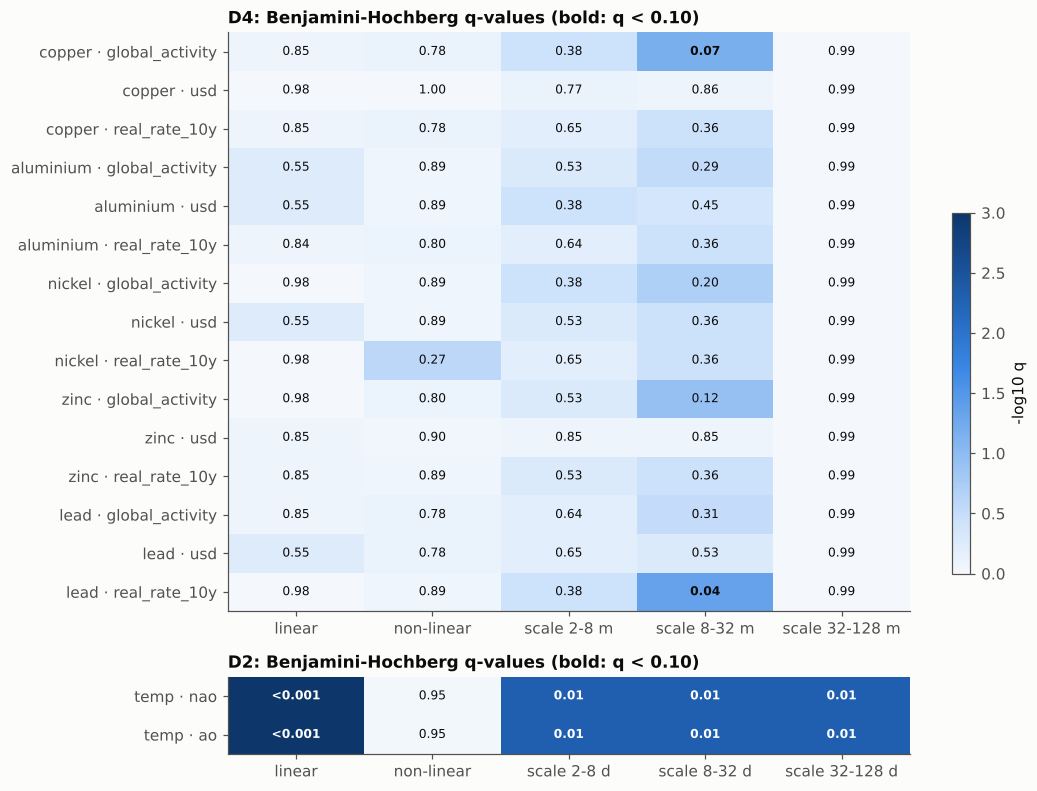

In [27]:
def q_heatmap(table, path):
    parts = [g for _, g in table.groupby("dataset", sort=False)]
    fig, axes = plt.subplots(len(parts), 1, figsize=(10, 0.36 * len(table) + 2.4),
                             gridspec_kw={"height_ratios": [len(g) for g in parts]})
    for ax, g in zip(axes, parts):
        cols = [c for c in g.columns if c.endswith(" q") and g[c].notna().all()]
        q = g[cols].to_numpy()
        im = ax.imshow(-np.log10(np.clip(q, 1e-3, 1)), cmap=SEQUENTIAL, vmin=0, vmax=3, aspect="auto")
        ax.set_xticks(range(len(cols)), [c[:-2] for c in cols])
        ax.set_yticks(range(len(g)), [f"{r.target} · {r.exogenous}" for r in g.itertuples()])
        for i in range(q.shape[0]):
            for j in range(q.shape[1]):
                ax.text(j, i, "<0.001" if q[i, j] < 0.001 else f"{q[i, j]:.2f}", ha="center", va="center",
                        fontsize=8, color="white" if q[i, j] < 0.03 else INK,
                        fontweight="bold" if q[i, j] < ALPHA else "normal")
        ax.set_title(f"{g['dataset'].iloc[0]}: Benjamini-Hochberg q-values (bold: q < 0.10)", loc="left")
        ax.grid(False)
    fig.colorbar(im, ax=axes, label="-log10 q", shrink=0.5)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


q_heatmap(gc_all, RESULTS / "figures" / "fig_ch03_02_granger_q.png")

**What this tells us.**

*D4.* Neither the linear nor the non-linear test finds that a driver helps forecast next month's change in a metal
price. The smallest linear q-value is 0.55, and the smallest non-linear q-value is 0.27 (nickel and the real rate,
raw p = 0.018). Scale by scale, two pairs pass at 10 %, both in the 8-to-32-month band: global activity for copper
(p = 0.009, q = 0.067) and the real rate for lead (p = 0.003, q = 0.045). Global activity for zinc (q = 0.12) and
nickel (q = 0.20) points the same way but does not pass. The predictive link from global activity therefore sits
at periods of one to three years, where Section 6 also found coherence, and it is lost in the month-to-month noise
that the full-band test sees.

*D2.* Both indices help forecast tomorrow's temperature anomaly beyond its own past by a wide margin (with 6 lags,
F = 22.7 for NAO and 23.6 for AO, q < 0.001), and they do so in all three bands (p = 0.005, the smallest value 199
surrogates can give). The non-linear test finds nothing more (q = 0.95), so the link is linear. This reverses the
coherence verdict. The effect is modest (Section 10 puts the rank correlation near 0.23), but 9,550 days are enough
for a regression to detect a modest, steady effect with great confidence. Coherence, in contrast, needs a strong
local correlation at a given period and time, and NAO reaches that only in scattered winter patches.

## 9 · SURD: what each source adds, alone, shared or only in combination

A correlation measures how two variables move together at the same time. It cannot say whether a covariate tells
us something about the target's **future** that the target's own past does not, nor whether two covariates, such
as NAO and AO, tell the same story. SURD (synergistic–unique–redundant decomposition) answers both questions in
units of information (bits).

It takes the future of the target, $T^+ = y_{t+1}$, and the present values of a set of sources
$Q = (Q_1, \dots, Q_N)$, for example the target's own value and one driver. It then splits the uncertainty
(entropy) of $T^+$ into pieces:

$$H(T^+) = \sum_{g} \Delta I^{R}_ {g} + \sum_{j} \Delta I^{U}_ {j} + \sum_{g} \Delta I^{S}_ {g} + \Delta I_{\text{leak}}. \tag{S1}$$

Here $j$ runs over the single sources and $g$ over groups of them. The first three sums add up to the mutual
information $I(T^+;\thinspace Q)$, the information that the sources
together carry about $T^+$.

- **Redundant** information ($R$) is told by several sources alike.
- **Unique** information ($U$) comes from one source only.
- **Synergistic** information ($S$) appears only when sources are read together. The textbook example is the
  exclusive "or": neither input alone says anything about the output, but together they determine it.
- The **leak** is the part of the uncertainty that the sources cannot explain.

#### How the pieces are found

The building block is the specific mutual information between one target state $\tau$ and a subset $A$
of the sources:

$$\tilde{i}(\tau; Q_A) = \sum_{q} p(q_A \mid \tau) \log_2 \frac{p(\tau \mid q_A)}{p(\tau)}, \qquad \sum_\tau p(\tau)\thinspace \tilde{i}(\tau; Q_A) = I(T^+; Q_A). \tag{S2}$$

It measures how much the sources in $A$ tell us about the target landing in state $\tau$. For each $\tau$,
the values for the single sources are sorted from smallest to largest. The smallest is shared by every source
(redundant); each further step is shared by the sources whose value is at least that large; the last step belongs
only to the most informative source (unique). Groups of sources that together carry more than any single source
add the excess as synergy. Averaging over $\tau$ with weights $p(\tau)$ gives the terms of (S1), and the leak is
$\Delta I_{\text{leak}} = H(T^+ \mid Q)$. The notebook reports every term as a **share of $H(T^+)$**, so
the shares and the leak add up to 1.

#### Estimation

Probabilities come from histograms with equal-count bins: 4 per variable for the 533 months of D4 and 5 for the
9,550 days of D2. With three variables (the target's future and two sources), the joint histogram then has 64
cells for D4, holding about 8 values each on average, and 125 cells for D2, holding about 76. Estimates of this
kind are biased upwards, so the notebook repeats the decomposition 200 times with every driver phase-randomised
(equation G3) and counts a driver as informative only if its share beats that baseline. The p-value is the
fraction of surrogates with a driver share at least as large, followed by the Benjamini–Hochberg correction. The
decomposition itself is computed with the `surd` package published by the method's authors.

In [28]:
import surd as surd_pkg


def equal_count_bins(v, bins):
    """Bin index 0..bins-1 with (almost) the same number of values in every bin."""
    ranks = stats.rankdata(v, method="ordinal") - 1
    return (ranks * bins // len(ranks)).astype(int)


def surd_shares(target, sources, lag=1, bins=4):
    """SURD of target[t + lag] given sources[t], as shares of the target's entropy.

    `sources` is a dict name -> series (same length as target). Returns a dict with
    'unique <name>', 'redundant <a+b...>', 'synergy <a+b...>' shares and 'leak';
    together they add up to 1.
    """
    names = list(sources)
    cols = [equal_count_bins(np.asarray(target, float)[lag:], bins)]
    cols += [equal_count_bins(np.asarray(sources[k], float)[:-lag], bins) for k in names]
    edges = [np.arange(bins + 1) - 0.5] * len(cols)
    hist, _ = np.histogramdd(np.column_stack(cols), bins=edges)
    p_target = hist.sum(axis=tuple(range(1, hist.ndim))) / hist.sum()
    h_target = -np.sum(p_target[p_target > 0] * np.log2(p_target[p_target > 0]))
    i_r, i_s, _, leak = surd_pkg.surd(hist)
    out = {}
    for key, val in i_r.items():
        label = "unique " + names[key[0] - 1] if len(key) == 1 else "redundant " + "+".join(names[k - 1] for k in key)
        out[label] = float(val / h_target)
    for key, val in i_s.items():
        out["synergy " + "+".join(names[k - 1] for k in key)] = float(val / h_target)
    out["leak"] = float(leak)
    return out


def surd_with_null(target, sources, drivers, lag=1, bins=4, n_surrogates=100, seed=0):
    """SURD shares plus a null: the same shares with every driver phase-randomised.

    Returns (shares, null) where null is a DataFrame of surrogate shares (one row per
    surrogate). Terms that involve a driver should exceed their null 95th percentile.
    """
    import pandas as pd
    rng = np.random.default_rng(seed)
    shares = surd_shares(target, sources, lag, bins)
    rows = []
    for _ in range(n_surrogates):
        fake = {k: (phase_randomise(v, rng) if k in drivers else v) for k, v in sources.items()}
        rows.append(surd_shares(target, fake, lag, bins))
    return shares, pd.DataFrame(rows)

In [29]:
rng = np.random.default_rng(11)
a, b, noise = rng.standard_normal(20_000), rng.standard_normal(20_000), 0.3 * rng.standard_normal(20_000)
toys = {
    "b is a copy of a; target = a": (np.roll(a, 1) + noise, {"a": a, "b": a + 1e-9 * b}, 4),
    "b is irrelevant; target = a": (np.roll(a, 1) + noise, {"a": a, "b": b}, 4),
    "target = a times b (signs)": (np.roll(a * b, 1), {"a": a, "b": b}, 2),
}
pd.DataFrame({name: surd_shares(tgt, src, lag=1, bins=k) for name, (tgt, src, k) in toys.items()}).T.round(3)

,unique a,unique b,redundant a+b,synergy a+b,leak
b is a copy of a; target = a,0.000,0.0,0.536,0.000,0.464
b is irrelevant; target = a,0.536,0.0,0.000,0.001,0.463
target = a times b (signs),0.000,0.0,0.000,0.961,0.039


**What this tells us.** The decomposition behaves as its definitions say. When b is a copy of a, everything a
tells about the target is booked as redundant (0.536 of the target's entropy), and neither source has unique
information. When b is irrelevant, the same 0.536 is unique to a. When the target is the product of a and b, read
through its sign, neither source says anything alone and 96 % of the entropy is synergy; the remaining 4 % of leak
comes from bin edges that do not fall exactly at zero.

In [30]:
SURD_BINS, N_SURR_SURD = {"D4": 4, "D2": 5}, 200


def driver_terms(shares, drivers):
    # SURD terms (unique, redundant, synergy) that involve at least one of the drivers
    return [k for k in shares if k != "leak" and any(d in k.split(" ", 1)[1].split("+") for d in drivers)]


def surd_pair_table(targets, drivers, target_data, driver_data, dataset):
    rows = []
    for target in targets:
        for exog in drivers:
            y = target_data[target].to_numpy()
            shares, null = surd_with_null(y, {"own": y, exog: driver_data[exog].to_numpy()}, [exog], lag=1,
                                          bins=SURD_BINS[dataset], n_surrogates=N_SURR_SURD, seed=2026)
            terms = driver_terms(shares, [exog])
            obs, null_tot = sum(shares[k] for k in terms), null[terms].sum(axis=1)
            rows.append({"dataset": dataset, "target": target, "exogenous": exog,
                         "unique own": shares["unique own"], "redundant": shares[f"redundant own+{exog}"],
                         "synergy": shares[f"synergy own+{exog}"], "unique driver": shares[f"unique {exog}"],
                         "leak": shares["leak"], "driver share": obs, "null 95 %": null_tot.quantile(0.95),
                         "SURD p": (1 + (null_tot >= obs).sum()) / (1 + N_SURR_SURD)})
    return add_q(pd.DataFrame(rows))


t0 = time.time()
surd_d4 = surd_pair_table(METALS, DRIVERS, D4_IN, D4_EX, "D4")
print(f"15 decompositions with {N_SURR_SURD} surrogates each: {time.time() - t0:.0f} s")
surd_d4.round(3)

15 decompositions with 200 surrogates each: 2 s


,dataset,target,exogenous,unique own,redundant,synergy,unique driver,leak,driver share,null 95 %,SURD p,SURD q
0,D4,copper,global_activity,0.020,0.012,0.022,0.005,0.942,0.039,0.047,0.289,0.481
1,D4,copper,usd,0.026,0.006,0.020,0.000,0.949,0.025,0.046,0.836,0.836
2,D4,copper,real_rate_10y,0.027,0.005,0.026,0.000,0.942,0.031,0.045,0.562,0.703
3,D4,aluminium,global_activity,0.018,0.008,0.034,0.006,0.934,0.048,0.053,0.124,0.388
4,D4,aluminium,usd,0.022,0.004,0.027,0.001,0.946,0.032,0.045,0.507,0.692
5,D4,aluminium,real_rate_10y,0.022,0.004,0.023,0.000,0.951,0.027,0.048,0.731,0.836
6,D4,nickel,global_activity,0.036,0.018,0.029,0.002,0.916,0.048,0.060,0.234,0.481
7,D4,nickel,usd,0.043,0.010,0.017,0.000,0.929,0.028,0.047,0.781,0.836
8,D4,nickel,real_rate_10y,0.046,0.007,0.031,0.000,0.915,0.038,0.048,0.279,0.481
9,D4,zinc,global_activity,0.014,0.017,0.034,0.000,0.934,0.052,0.055,0.080,0.388


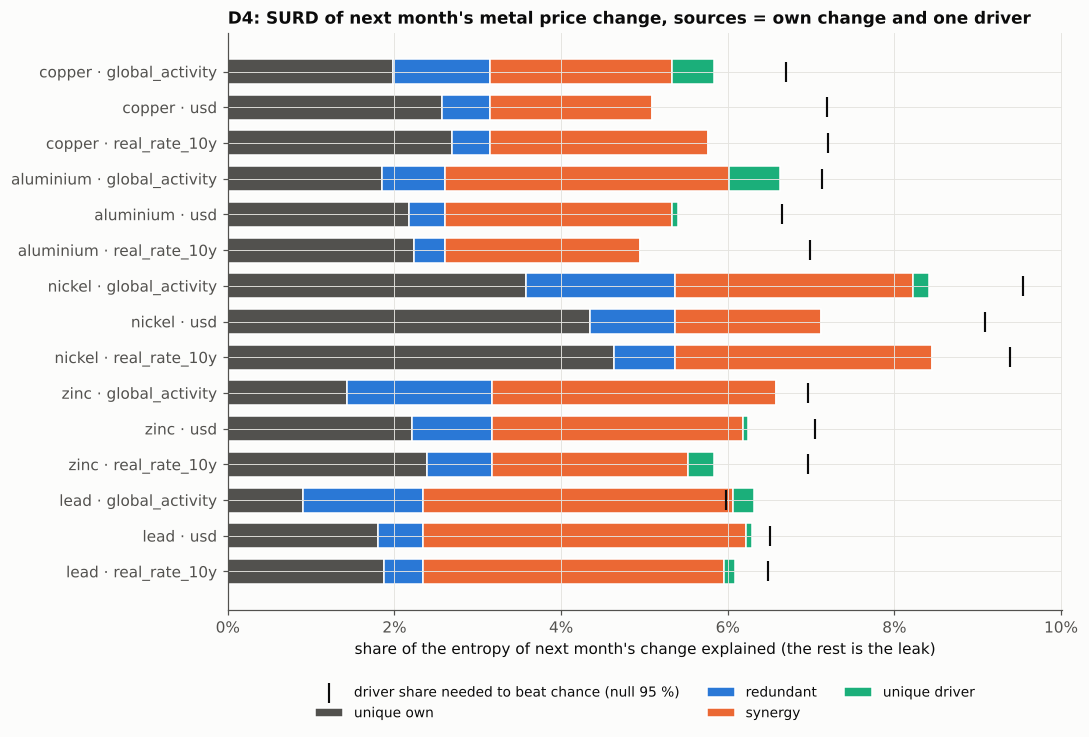

In [31]:
parts = ["unique own", "redundant", "synergy", "unique driver"]
labels = [f"{r.target} · {r.exogenous}" for r in surd_d4.itertuples()]
fig, ax = plt.subplots(figsize=(10, 6.8))
left = np.zeros(len(surd_d4))
for part, color in zip(parts, [INK_2, COLORS[0], COLORS[1], COLORS[2]]):
    ax.barh(labels, surd_d4[part], left=left, color=color, label=part, height=0.7, edgecolor="white", linewidth=1)
    left += surd_d4[part].to_numpy()
ax.scatter(surd_d4["null 95 %"] + surd_d4["unique own"], labels, marker="|", s=160, color=INK, zorder=3,
           label="driver share needed to beat chance (null 95 %)")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("share of the entropy of next month's change explained (the rest is the leak)")
ax.set_title("D4: SURD of next month's metal price change, sources = own change and one driver", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "fig_ch03_02_surd_D4.png", dpi=150, bbox_inches="tight")
plt.show()

**What this tells us.** Next month's change in a metal price is hard to predict from this month's information. The
metal's own change and one driver together explain only 5 to 8.5 % of its entropy (leak 0.915 to 0.951). The
driver's part (redundant, synergy and unique together) is 2.5 to 5.4 %, and none beats its surrogate baseline
after the correction (smallest q 0.39; lead with global activity has the smallest raw p, 0.030). Almost all of it
is synergy, the term that estimation noise inflates most on 533 months, and no driver's unique part exceeds 0.6 %.

The lead table further down adds a faint pattern. Eight of its 45 D4 cells beat the 95th percentile, where about
two would be expected by chance, and seven of the eight involve global activity, mostly at 3 and 6 months. The
margins are small (at most 1.1 points, aluminium at 6 months), and the cells are not independent tests. Still,
the pattern fits the rest of the evidence: global activity carries a little information about metal prices that
builds with the lead time, and no usable month-to-month signal.

#### D2: NAO, AO and the temperature's own past

First comes the same pairwise decomposition as for D4: what does each index add to today's anomaly about
tomorrow's? Then a decomposition with NAO and AO alone, which answers a question that a correlation between the two
indices cannot: of what they tell us about tomorrow's temperature, how much is shared and how much is particular
to each?

In [32]:
surd_d2 = surd_pair_table(["temp"], ["nao", "ao"], pd.DataFrame({"temp": anomaly}), d2, "D2")
display(surd_d2.round(4))
shares, null = surd_with_null(anomaly.to_numpy(), {"nao": d2["nao"].to_numpy(), "ao": d2["ao"].to_numpy()},
                              ["nao", "ao"], lag=1, bins=SURD_BINS["D2"], n_surrogates=N_SURR_SURD, seed=2026)
joint = 1 - shares["leak"]
overlap = {k: v / joint for k, v in shares.items() if k != "leak"}
print(f"NAO and AO together explain {joint:.2%} of the entropy of tomorrow's anomaly "
      f"(unrelated indices: at most {1 - null['leak'].quantile(0.05):.2%} in 95 % of surrogates).")
print("Split of that information: " + ", ".join(f"{k} {v:.0%}" for k, v in overlap.items()))
pd.DataFrame({"share of entropy": shares, "null 95 %": null.quantile(0.95)}).round(4)

,dataset,target,exogenous,unique own,redundant,synergy,unique driver,leak,driver share,null 95 %,SURD p,SURD q
0,D2,temp,nao,0.2014,0.0189,0.0065,0.0,0.7732,0.0254,0.0050,0.005,0.005
1,D2,temp,ao,0.2008,0.0194,0.0076,0.0,0.7722,0.0270,0.0048,0.005,0.005


NAO and AO together explain 2.99% of the entropy of tomorrow's anomaly (unrelated indices: at most 0.61% in 95 % of surrogates).
Split of that information: unique nao 5%, unique ao 7%, redundant nao+ao 58%, synergy nao+ao 30%


,share of entropy,null 95 %
unique nao,0.0014,0.0013
unique ao,0.0020,0.0009
redundant nao+ao,0.0174,0.0009
synergy nao+ao,0.0090,0.0042
leak,0.9701,0.9965


#### How far ahead?

The Granger tests and the SURD above look one step ahead, but the forecasts start at 3 months (D4) and 7 days
(D2). The same pairwise SURD with the target further in the future, $T^+ = y_{t+\ell}$, shows how quickly a
covariate's information fades. The table gives the driver's share minus the 95th percentile of its null
distribution: positive values beat chance at that lead.

In [33]:
LEADS = {"D4": [1, 3, 6], "D2": [1, 3, 7, 14]}
rows = []
for dataset, targets, drivers, tdata, ddata in [("D4", METALS, DRIVERS, D4_IN, D4_EX),
                                                ("D2", ["temp"], ["nao", "ao"], pd.DataFrame({"temp": anomaly}), d2)]:
    for target in targets:
        for exog in drivers:
            y = tdata[target].to_numpy()
            for lead in LEADS[dataset]:
                shares, null = surd_with_null(y, {"own": y, exog: ddata[exog].to_numpy()}, [exog], lag=lead,
                                              bins=SURD_BINS[dataset], n_surrogates=100, seed=2026)
                terms = driver_terms(shares, [exog])
                obs = sum(shares[k] for k in terms)
                rows.append({"dataset": dataset, "target": target, "exogenous": exog, "lead": lead,
                             "excess over null": obs - null[terms].sum(axis=1).quantile(0.95)})
surd_leads = pd.DataFrame(rows).pivot_table(index=["dataset", "target", "exogenous"], columns="lead",
                                            values="excess over null", sort=False)
surd_leads.style.format(precision=4, na_rep="–").set_caption(
    "A dash (–) marks a lead not used for that dataset: D4 uses 1, 3 and 6 months, D2 uses 1, 3, 7 and 14 days.")

**What this tells us.** Today's temperature anomaly is by far the best guide to tomorrow's: on its own it carries
20 % of the entropy as unique information. NAO and AO each add 2.5 to 2.7 % (null 95th percentile 0.5 %;
p = 0.005, the smallest value 200 surrogates allow), but none of it is unique to the index. Most of it (1.9 %) is
redundant with today's anomaly, largely because yesterday's weather pattern has already shaped today's
temperature. The rest (about 0.7 %) appears only when the index is read together with today's anomaly.

Read on their own, NAO and AO explain 3.0 % of the entropy of tomorrow's anomaly (unrelated indices: at most
0.6 %). Of that, 58 % is shared between them and 30 % is synergy; 7 % is unique to AO, and the 5 % unique to NAO is
no more than the surrogates give. The two indices therefore mostly tell the same story about temperature. A
correlation between the two series could not show this, because it says nothing about the temperature.

The lead table shows how fast this fades. The excess over chance is 2.0 points for NAO and 2.2 for AO one day
ahead, 1.2 and 1.9 at three days, 0.2 and 0.7 at seven days, and zero at 14 days. The indices help over the first
few days and add little at the 7-to-90-day horizons of this chapter.

## 10 · Rolling correlation: is the relation stable over time?

Every number so far summarises the whole in-sample period. A relation can strengthen, fade or flip sign as
conditions change, and a covariate whose link comes and goes is a risky input for a model that only sees a recent
window of context. A rolling correlation shows this directly. We use Spearman's rank correlation, which works on
ranks and so is not thrown off by the large one-off moves of metal prices and climate indices. Within each trailing
window of $w$ points,

$$\rho_S = 1 - \frac{6 \sum_{t} d_t^2}{w (w^2 - 1)}, \tag{RC1}$$

where $d_t$ is the difference between the ranks of $y_t$ and $x_{t-\ell}$ within the window. With $\ell = 0$ the two
are compared in the same period; with $\ell = 1$ the driver is taken one step earlier, which is the version a
forecaster can use.

For unrelated series, the transformed correlation $\operatorname{artanh} \rho_S$ is approximately normal with
variance $1.06/(w - 3)$, so about 95 % of their values fall inside the band

$$\pm 1.96 \sqrt{1.06/(w - 3)}.$$

The band ignores autocorrelation within the window, so it is a little too narrow for persistent inputs such as
global activity; read it as a guide. The windows are 60 months (five years) for D4 and 365 days (one year) for D2.

In [34]:
def rolling_spearman(y, x, window, lag=0):
    """Spearman correlation of y[t] and x[t - lag] in trailing windows of `window` points.

    Returns (correlation series indexed by window end, half-width of an approximate 95 %
    band under independence, 1.96 * sqrt(1.06 / (window - 3)); Fieller et al., 1957).
    """
    import pandas as pd
    from numpy.lib.stride_tricks import sliding_window_view
    pair = pd.concat([y.rename("y"), x.shift(lag).rename("x")], axis=1).dropna()
    wy = sliding_window_view(pair["y"].to_numpy(), window)
    wx = sliding_window_view(pair["x"].to_numpy(), window)
    ry = wy.argsort(axis=1).argsort(axis=1).astype(float)
    rx = wx.argsort(axis=1).argsort(axis=1).astype(float)
    ry -= ry.mean(axis=1, keepdims=True)
    rx -= rx.mean(axis=1, keepdims=True)
    rho = (ry * rx).sum(axis=1) / np.sqrt((ry ** 2).sum(axis=1) * (rx ** 2).sum(axis=1))
    return pd.Series(rho, index=pair.index[window - 1:]), 1.96 * np.sqrt(1.06 / (window - 3))

In [35]:
WINDOW = {"D4": 60, "D2": 365}


def rolling_summary(y, x, window, dataset, target, exog):
    r0, band = rolling_spearman(y, x, window, lag=0)
    r1, _ = rolling_spearman(y, x, window, lag=1)
    sign = np.sign(r1.median())
    return {"dataset": dataset, "target": target, "exogenous": exog, "median rho (same step)": r0.median(),
            "median rho (driver one step earlier)": r1.median(), "band": band,
            "share of windows outside band (one step earlier)": float((r1.abs() > band).mean()),
            "share outside band with the median's sign": float((sign * r1 > band).mean())}, r0, r1


rolling_rows, rolling_series = [], {}
for target in METALS:
    for exog in DRIVERS:
        row, r0, r1 = rolling_summary(D4_IN[target], D4_EX[exog], WINDOW["D4"], "D4", target, exog)
        rolling_rows.append(row)
        rolling_series[("D4", target, exog)] = (r0, r1, row["band"])
for exog in ["nao", "ao"]:
    row, r0, r1 = rolling_summary(anomaly, d2[exog], WINDOW["D2"], "D2", "temp", exog)
    rolling_rows.append(row)
    rolling_series[("D2", "temp", exog)] = (r0, r1, row["band"])
rolling = pd.DataFrame(rolling_rows)
rolling.to_csv(RESULTS / "tables" / "table_rolling_spearman.csv", index=False)
rolling.round(3)

,dataset,target,exogenous,median rho (same step),median rho (driver one step earlier),band,share of windows outside band (one step earlier),share outside band with the median's sign
0,D4,copper,global_activity,0.039,0.009,0.267,0.119,0.082
1,D4,copper,usd,-0.298,-0.118,0.267,0.066,0.066
2,D4,copper,real_rate_10y,0.107,0.006,0.267,0.000,0.000
3,D4,aluminium,global_activity,0.038,-0.004,0.267,0.043,0.018
4,D4,aluminium,usd,-0.295,-0.072,0.267,0.164,0.164
5,D4,aluminium,real_rate_10y,0.088,-0.023,0.267,0.009,0.000
6,D4,nickel,global_activity,0.037,0.005,0.267,0.137,0.075
7,D4,nickel,usd,-0.249,-0.121,0.267,0.265,0.265
8,D4,nickel,real_rate_10y,0.102,0.033,0.267,0.089,0.059
9,D4,zinc,global_activity,0.033,0.023,0.267,0.171,0.064


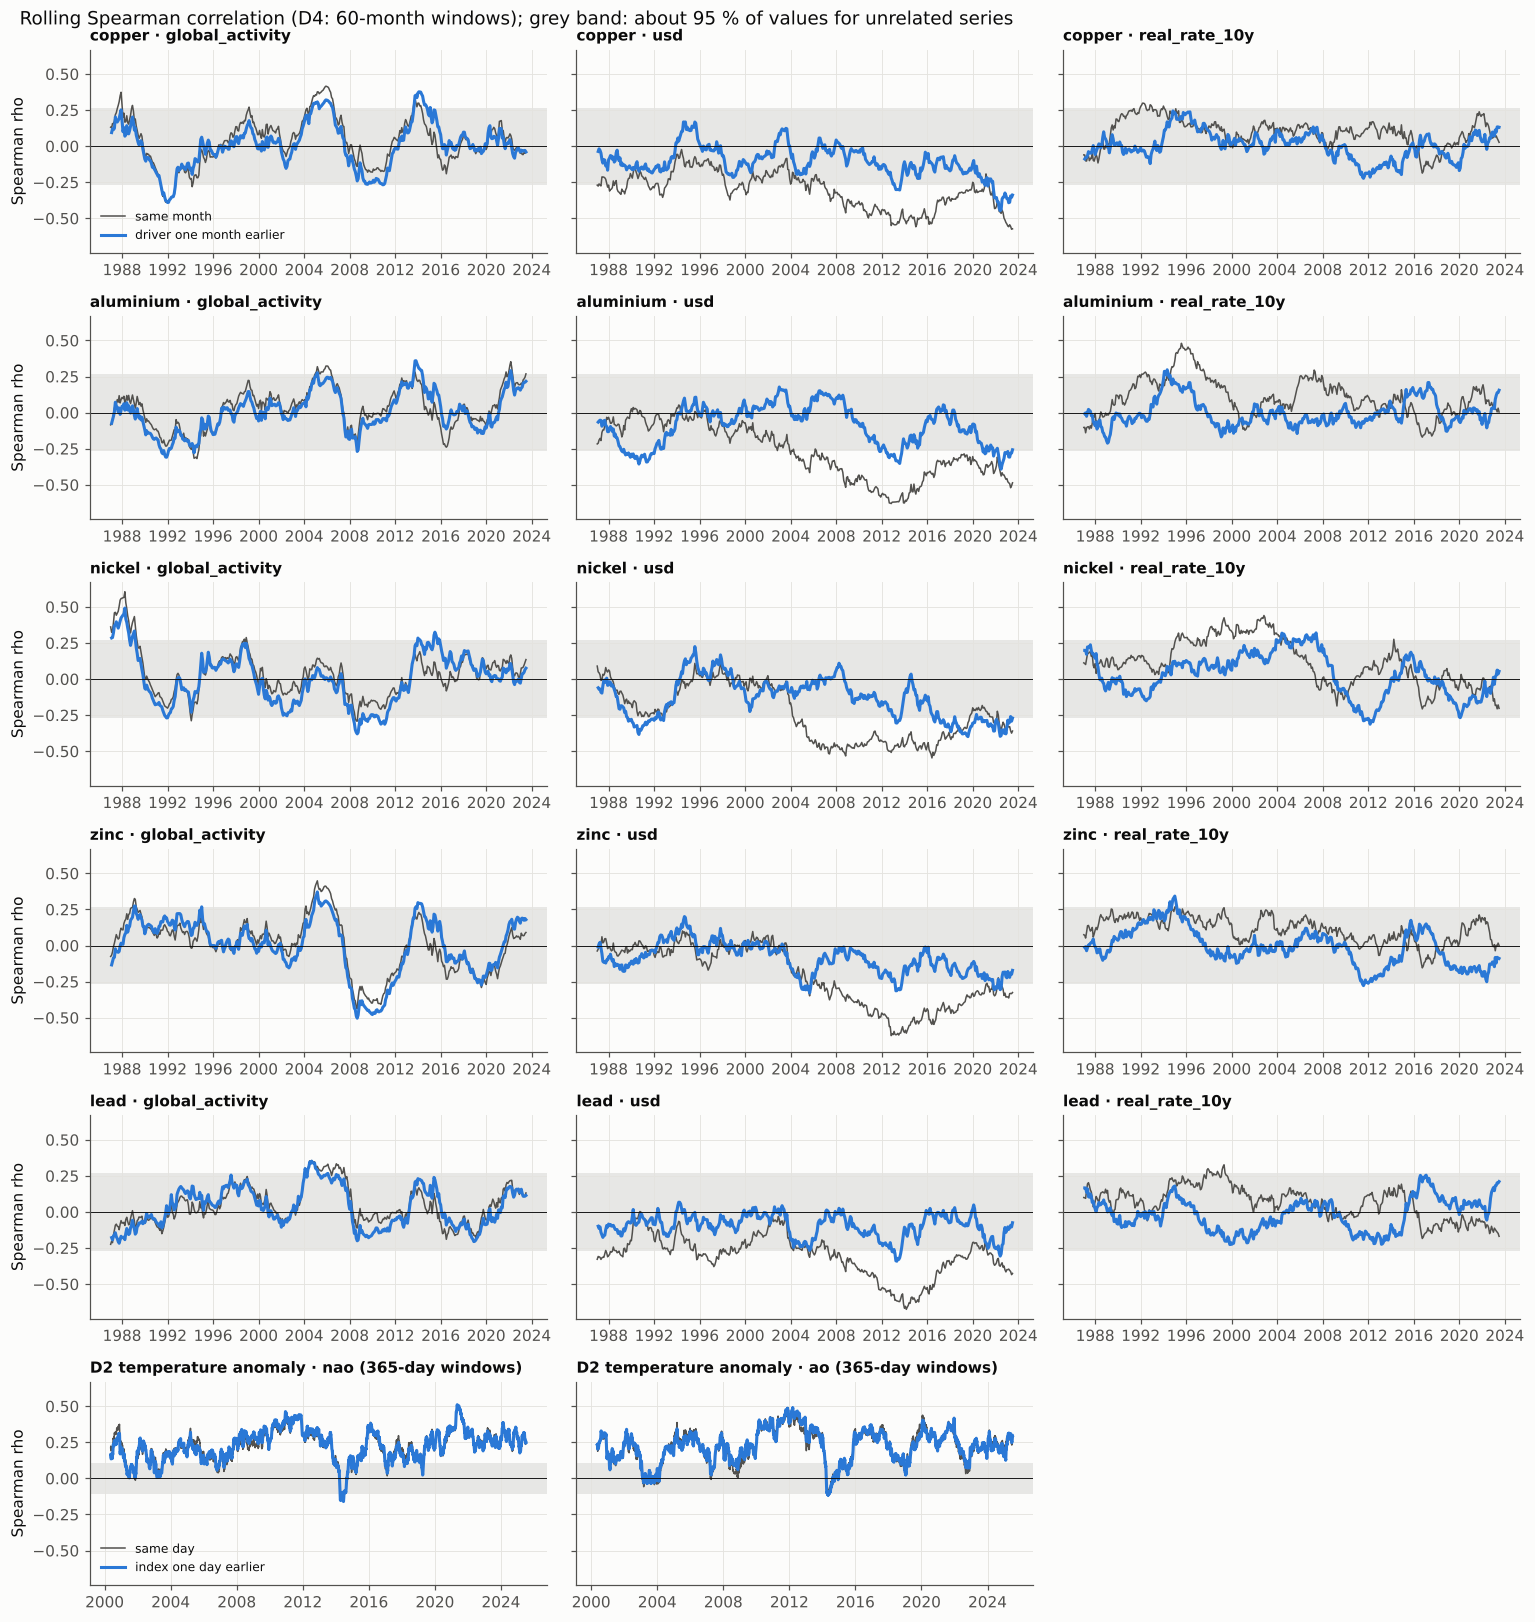

In [36]:
fig, axes = plt.subplots(len(METALS) + 1, 3, figsize=(14, 15), sharey=True)
for i, target in enumerate(METALS):
    for j, exog in enumerate(DRIVERS):
        r0, r1, band = rolling_series[("D4", target, exog)]
        ax = axes[i, j]
        ax.axhspan(-band, band, color=INK_2, alpha=0.12, lw=0)
        ax.plot(r0.index, r0, color=INK_2, lw=1, label="same month")
        ax.plot(r1.index, r1, color=COLORS[0], lw=2, label="driver one month earlier")
        ax.axhline(0, color=INK, lw=0.6)
        ax.set_title(f"{target} · {exog}", loc="left", fontsize=10)
for j, exog in enumerate(["nao", "ao"]):
    r0, r1, band = rolling_series[("D2", "temp", exog)]
    ax = axes[-1, j]
    ax.axhspan(-band, band, color=INK_2, alpha=0.12, lw=0)
    ax.plot(r0.index, r0, color=INK_2, lw=1, label="same day")
    ax.plot(r1.index, r1, color=COLORS[0], lw=2, label="index one day earlier")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set_title(f"D2 temperature anomaly · {exog} (365-day windows)", loc="left", fontsize=10)
axes[-1, 2].axis("off")
axes[0, 0].legend(loc="lower left", frameon=False, fontsize=8)
axes[-1, 0].legend(loc="lower left", frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Spearman rho")
fig.suptitle("Rolling Spearman correlation (D4: 60-month windows); grey band: about 95 % of values for unrelated series",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "fig_ch03_02_rolling_spearman.png", dpi=150)
plt.show()

**What this tells us.**

*D4.* With the driver taken one month earlier, no pair's correlation lies outside the band in more than about a
quarter of the windows (the largest share is nickel with the dollar, 27 %), and the medians lie between −0.12 and
+0.03. In the same month the picture changes. The dollar's median correlation with metal price changes is −0.22 to
−0.30, and it is near or below −0.5 for all five metals around 2012 to 2014: the familiar inverse relation between
the dollar and commodity prices. A past-only covariate cannot use a same-month relation. It would help only if the
future dollar were known, which is what the oracle run of the covariate experiments assumes. Global activity swings
sign: its correlation with copper runs from about −0.4 around 1992 to +0.4 around 2005 and back below zero in 2008
to 2010. Its average link is therefore weak, even where the coherence maps find episodes.

*D2.* NAO and AO one day earlier correlate with the temperature anomaly at a median of 0.23. The value lies outside
the band in 88 % and 85 % of the 365-day windows, with a single dip to about zero around 2014: a stable, modest
relation.

## 11 · All the evidence: what to expect from each covariate

One row per covariate–target pair, with four lines of evidence:

- **WCA verdict** (Sections 5 to 7): coherence at the periods of the forecast horizons, with calibrated
  thresholds;
- **Granger** (Section 8): supportive if the linear, the non-linear or any by-scale test has $q < 0.10$;
- **SURD** (Section 9): supportive if the information involving the driver beats the surrogate baseline
  ($q < 0.10$);
- **rolling** (Section 10): supportive if the correlation with the driver one step earlier lies outside the band,
  with the same sign, in at least half of the windows.

#### The rule

The coherence verdict is the starting point, because it is the only test that looks at long periods, and those
matter for the longest horizons. The verdict moves **up one step** (drop to weak, weak to keep) when at least two
of the other three lines support the covariate, and it is never moved down, because the one-step tests cannot see
a relation that works only over years. Then, if SURD shows that two covariates of the same dataset mostly tell the
same story (more than half of what they explain together is redundant), the one with the stronger linear Granger
statistic keeps its verdict and the other is marked *drop*: once the first is in, the second should add little.
The known-future covariates of D2 (Fourier terms and day length) are available over the whole horizon, so for them
the verdict only says how much they are expected to help.

> **Note: the verdict is an expectation, not a filter.** Every covariate of D2 and D4, including those marked
> *drop*, goes into the forecasting experiments. The top-performing models are run with and without the
> covariates, and the gain in accuracy is measured directly. The verdicts here are the prediction that this
> comparison tests: *keep* means we expect a clear gain, *weak* a small or unstable one, and *drop* means the tests
> found no evidence of a gain. There are four reasons not to filter on these tests:
>
> 1. They look at one covariate, or one pair, at a time. A model sees all of them together, and Section 9 found
>    that part of what NAO and AO tell about temperature appears only in combination (synergy).
> 2. Most of them look one step ahead, and the linear ones only at linear links. Foundation models forecast
>    several steps ahead and can use non-linear patterns.
> 3. *Drop* means that no evidence was found in this sample. It is not evidence that the covariate is useless.
> 4. Only out-of-sample accuracy settles whether a covariate improves a forecast. Adding an uninformative
>    covariate can also make some models worse, and the with-and-without comparison shows that too.

In [37]:
LADDER = ["drop", "weak", "keep"]
wca = pd.concat([verdicts_d4.assign(dataset="D4"), verdicts_d2.assign(dataset="D2")], ignore_index=True)
surd_all = pd.concat([surd_d4, surd_d2], ignore_index=True)
keys = ["dataset", "target", "exogenous"]
evidence = (wca[keys + ["verdict"]].rename(columns={"verdict": "WCA verdict"})
            .merge(gc_all, on=keys, how="left")
            .merge(surd_all[keys + ["driver share", "SURD q"]], on=keys, how="left")
            .merge(rolling, on=keys, how="left"))
gc_q = [c for c in gc_all.columns if c.endswith(" q")]
tested = evidence["linear q"].notna()
evidence["Granger"] = (evidence[gc_q] < ALPHA).any(axis=1)
evidence["SURD"] = evidence["SURD q"] < ALPHA
evidence["rolling"] = evidence["share outside band with the median's sign"] >= 0.5
evidence["support (of 3)"] = evidence[["Granger", "SURD", "rolling"]].sum(axis=1).where(tested)


def final_verdict(r):
    if pd.isna(r["support (of 3)"]):
        return r["WCA verdict"]
    return LADDER[min(LADDER.index(r["WCA verdict"]) + int(r["support (of 3)"] >= 2), 2)]


evidence["verdict"] = evidence.apply(final_verdict, axis=1)
evidence["note"] = np.where(tested, "", "deterministic: coherence only")
shared = overlap["redundant nao+ao"]
both = evidence.index[(evidence["dataset"] == "D2") & evidence["exogenous"].isin(["nao", "ao"])
                      & (evidence["verdict"] != "drop")]
if shared > 0.5 and len(both) == 2:
    stronger, weaker = evidence.loc[both, "linear F"].idxmax(), evidence.loc[both, "linear F"].idxmin()
    evidence.loc[weaker, "verdict"] = "drop"
    evidence.loc[weaker, "note"] = (f"redundant with {evidence.loc[stronger, 'exogenous']}: {shared:.0%} of what "
                                    "the two indices tell about temperature is shared (SURD)")
evidence.to_csv(RESULTS / "tables" / "table_covariate_verdicts.csv", index=False)
summary = evidence.groupby(["dataset", "exogenous"], sort=False)["verdict"].agg(
    lambda v: "keep" if (v == "keep").any() else "weak" if (v == "weak").any() else "drop")
print("Expected value of each covariate (keep if kept for any target; all are used in the forecasting notebooks):")
for (ds, ex), v in summary.items():
    print(f"  {ds} {ex:16s} {v}")
shown = evidence[keys + ["WCA verdict", "Granger", "SURD", "rolling", "support (of 3)", "verdict", "note"]].copy()
tests3 = ["Granger", "SURD", "rolling"]
shown[tests3] = shown[tests3].astype(object)
shown.loc[~tested, tests3] = "–"   # a deterministic covariate is not put through these tests
shown.style.format(precision=0, na_rep="–").set_caption(
    "A dash (–) means not tested: day length is deterministic (known for every future date), "
    "so only its coherence verdict is used (see the note column).")

Expected value of each covariate (keep if kept for any target; all are used in the forecasting notebooks):
  D4 global_activity  keep
  D4 usd              weak
  D4 real_rate_10y    weak
  D2 nao              drop
  D2 ao               weak
  D2 daylength_h      keep


,dataset,target,exogenous,WCA verdict,Granger,SURD,rolling,support (of 3),verdict,note
0,D4,copper,global_activity,weak,True,False,False,1,weak,
1,D4,copper,usd,weak,False,False,False,0,weak,
2,D4,copper,real_rate_10y,weak,False,False,False,0,weak,
3,D4,aluminium,global_activity,weak,False,False,False,0,weak,
4,D4,aluminium,usd,weak,False,False,False,0,weak,
5,D4,aluminium,real_rate_10y,weak,False,False,False,0,weak,
6,D4,nickel,global_activity,keep,False,False,False,0,keep,
7,D4,nickel,usd,weak,False,False,False,0,weak,
8,D4,nickel,real_rate_10y,drop,False,False,False,0,drop,
9,D4,zinc,global_activity,weak,False,False,False,0,weak,


**What this tells us.** The four lines of evidence agree on little for D4 and on a lot for D2.

In D4 the coherence verdicts stand. Global activity is kept for nickel and lead. It gains Granger support for
copper at 8-to-32-month periods, but that is one line of support, not two, so copper stays weak. The dollar and the
real rate stay weak. The dollar's strong same-month link (Section 10) is not something a past-only covariate can
use, and the real rate's one Granger pass (lead, 8 to 32 months) stands alone.

In D2, NAO and AO have all three predictive lines in their favour, so both move up from drop to weak. SURD shows
that 58 % of what they tell is shared, so once one of them is in, the other should add little. The one expected to
help is AO, on a near tie in the Granger statistic (23.6 against 22.7), and AO also keeps more information at 3
and 7 days. Day length is kept, together with the Fourier terms that carry the same annual cycle.

The expectations going into the forecasting notebooks are therefore:

- in D4, some gain from global activity and little from the dollar or the real rate;
- in D2, a clear gain from day length and the Fourier terms, a small gain from AO at the shortest horizons, and
  nothing extra from NAO once AO is in.

Every one of these covariates is still used there, and the top models are compared with and without them. The
causal wavelet bands of D2 are not screened, because they are built from the target itself; their value is measured
directly as forecast lift later in the chapter.

The expectations are written down before any model runs, so the forecasting results can confirm or contradict
them instead of being explained after the fact. Each one rests on two kinds of evidence: whether the covariate
moves with the target at the forecast periods, and whether its past helps to predict the target. The SURD lead
table also sets an expectation about timing: AO's help fades within a week, so any gain it brings should show at
the shortest horizons only.

## Key takeaways

- Wavelet coherence locates a relation in time and period; a single correlation coefficient averages it away.
- Significance needs a red-noise null and a multiple-testing correction: chance alone produces convincing patches
  of high coherence (the second check in Section 4).
- The direction of the arrows depends on the order of the inputs. Passing the exogenous variable first, and
  testing the convention on a synthetic pair, removes the ambiguity.
- For prices, changes are the right input, not levels: levels make unrelated trending series look coherent.
- The keep / weak / drop table is a transparent rule for what to expect from each covariate. Its thresholds come
  from independent series of the same length and persistence, so its false-alarm rate is known (about 5 % for
  *keep*).
- Coherence and predictive help are different questions. Granger tests ask whether the past of a covariate
  improves a forecast. Check every test on simulated data first, and use surrogates where the textbook
  distribution fails (filtered, band-by-band series).
- SURD replaces a single correlation coefficient with an account of information: what a covariate adds beyond the
  target's own past, and how much two covariates share. A surrogate baseline guards against estimation bias.
- A relation can be real on average and still unstable. Rolling correlations show whether it holds in the recent
  window that a zero-shot model actually sees.
- The verdicts are expectations, not a filter. Every covariate goes into the forecasting notebooks, where the
  top-performing models are run with and without covariates, so the gain is measured directly and the verdicts can
  be checked against it.

## References

The wavelet-coherence screening (Sections 1 to 7) follows the procedure of an earlier study by the authors of this book:

- Sengupta, S., Singh, S. K., & Chakraborty, T. (2025). Macroeconomic Forecasting for the G7 countries under Uncertainty Shocks. Preprint, [arXiv:2510.23347](https://arxiv.org/abs/2510.23347)

Methods and sources, in the order they appear:

- Wavelet transform, scales and cone of influence (Section 2, equation 1 follows eqs. 4 and 6 of this paper): Torrence, C., & Compo, G. P. (1998). A practical guide to wavelet analysis. *Bulletin of the American Meteorological Society*, 79(1), 61–78. [doi:10.1175/1520-0477(1998)079<0061:APGTWA>2.0.CO;2](https://doi.org/10.1175/1520-0477(1998)079%3C0061:APGTWA%3E2.0.CO;2)
- Wavelet coherence (Section 2): Torrence, C., & Webster, P. J. (1999). Interdecadal changes in the ENSO-monsoon system. *Journal of Climate*, 12(8), 2679–2690. [doi:10.1175/1520-0442(1999)012<2679:ICITEM>2.0.CO;2](https://doi.org/10.1175/1520-0442(1999)012%3C2679:ICITEM%3E2.0.CO;2)
- Coherence, smoothing and Monte Carlo significance (Sections 2 and 3): Grinsted, A., Moore, J. C., & Jevrejeva, S. (2004). Application of the cross wavelet transform and wavelet coherence to geophysical time series. *Nonlinear Processes in Geophysics*, 11(5/6), 561–566. [doi:10.5194/npg-11-561-2004](https://doi.org/10.5194/npg-11-561-2004)
- Reading the phase quadrants (Section 2): Aguiar-Conraria, L., & Soares, M. J. (2014). The continuous wavelet transform: moving beyond uni- and bivariate analysis. *Journal of Economic Surveys*, 28(2), 344–375. [doi:10.1111/joes.12012](https://doi.org/10.1111/joes.12012)
- False discovery rate (Sections 3 and 8): Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300. [doi:10.1111/j.2517-6161.1995.tb02031.x](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x)
- The R package that the code reproduces (Sections 1 to 3): Gouhier, T. C., Grinsted, A., & Simko, V. (2024). *biwavelet: Conduct univariate and bivariate wavelet analyses* (R package version 0.20.22). [CRAN](https://CRAN.R-project.org/package=biwavelet)
- Spurious relations between trending series (Section 6c): Granger, C. W. J., & Newbold, P. (1974). Spurious regressions in econometrics. *Journal of Econometrics*, 2(2), 111–120. [doi:10.1016/0304-4076(74)90034-7](https://doi.org/10.1016/0304-4076(74)90034-7)
- Global demand and commodity prices (Section 6): Kilian, L. (2009). Not all oil price shocks are alike: disentangling demand and supply shocks in the crude oil market. *American Economic Review*, 99(3), 1053–1069. [doi:10.1257/aer.99.3.1053](https://doi.org/10.1257/aer.99.3.1053)
- The dollar and commodity prices (Sections 6 and 10): Akram, Q. F. (2009). Commodity prices, interest rates and the dollar. *Energy Economics*, 31(6), 838–851. [doi:10.1016/j.eneco.2009.05.016](https://doi.org/10.1016/j.eneco.2009.05.016)
- Real interest rates and the carrying cost of commodities (Section 6): Frankel, J. A. (2008). The effect of monetary policy on real commodity prices. In J. Y. Campbell (Ed.), *Asset Prices and Monetary Policy* (pp. 291–333). University of Chicago Press. [NBER chapter](https://www.nber.org/books-and-chapters/asset-prices-and-monetary-policy/effect-monetary-policy-real-commodity-prices)
- NAO and English winter temperature (Section 7): Hurrell, J. W. (1995). Decadal trends in the North Atlantic Oscillation: regional temperatures and precipitation. *Science*, 269(5224), 676–679. [doi:10.1126/science.269.5224.676](https://doi.org/10.1126/science.269.5224.676)
- The Arctic Oscillation (Section 7): Thompson, D. W. J., & Wallace, J. M. (1998). The Arctic Oscillation signature in the wintertime geopotential height and temperature fields. *Geophysical Research Letters*, 25(9), 1297–1300. [doi:10.1029/98GL00950](https://doi.org/10.1029/98GL00950)
- Granger causality (Section 8): Granger, C. W. J. (1969). Investigating causal relations by econometric models and cross-spectral methods. *Econometrica*, 37(3), 424–438. [jstor.org/stable/1912791](https://www.jstor.org/stable/1912791)
- HC3 covariance (Section 8): MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics*, 29(3), 305–325. [RePEc record](https://ideas.repec.org/a/eee/econom/v29y1985i3p305-325.html)
- Non-linear Granger test and its bandwidth (Section 8): Diks, C., & Panchenko, V. (2006). A new statistic and practical guidelines for nonparametric Granger causality testing. *Journal of Economic Dynamics and Control*, 30(9–10), 1647–1669. [doi:10.1016/j.jedc.2005.08.008](https://doi.org/10.1016/j.jedc.2005.08.008)
- Testing VAR residuals for non-linear causality (Section 8): Hiemstra, C., & Jones, J. D. (1994). Testing for linear and nonlinear Granger causality in the stock price–volume relation. *Journal of Finance*, 49, 1639–1664. [jstor.org/stable/2329266](https://www.jstor.org/stable/2329266)
- Relations by time scale (Section 8): Ramsey, J. B., & Lampart, C. (1998). Decomposition of economic relationships by timescale using wavelets. *Macroeconomic Dynamics*, 2(1), 49–71. [Cambridge Core](https://www.cambridge.org/core/journals/macroeconomic-dynamics/article/abs/decomposition-of-economic-relationships-by-timescale-using-wavelets/5103A9AAEE780CCA5EAAFEC29ADC8375)
- Granger tests on filtered series (Section 8): Barnett, L., & Seth, A. K. (2011). Behaviour of Granger causality under filtering: theoretical invariance and practical application. *Journal of Neuroscience Methods*, 201(2), 404–419. [Sussex repository](https://sro.sussex.ac.uk/id/eprint/24387/)
- Phase-randomised surrogates (Sections 8 and 9): Theiler, J., Eubank, S., Longtin, A., Galdrikian, B., & Farmer, J. D. (1992). Testing for nonlinearity in time series: the method of surrogate data. *Physica D*, 58(1–4), 77–94. [doi:10.1016/0167-2789(92)90102-S](https://doi.org/10.1016/0167-2789(92)90102-S)
- SURD (Section 9): Martínez-Sánchez, Á., Arranz, G., & Lozano-Durán, A. (2024). Decomposing causality into its synergistic, unique, and redundant components. *Nature Communications*, 15, 9296. [doi:10.1038/s41467-024-53373-4](https://doi.org/10.1038/s41467-024-53373-4); code: the `surd` package, version 1.3.0, MIT licence ([PyPI](https://pypi.org/project/surd/), [GitHub](https://github.com/Computational-Turbulence-Group/SURD))
- Variance of the rank correlation (Section 10): Fieller, E. C., Hartley, H. O., & Pearson, E. S. (1957). Tests for rank correlation coefficients. I. *Biometrika*, 44(3/4), 470–481. [Biometrika issue](https://academic.oup.com/biomet/issue/44/3-4)